In [47]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [71]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.conversion_energy.tyndp import (
    load_tyndp_supply_capacities,
)
from cordex2energy.results.extreme_value import (
    calculate_climatological_baseline,
    compute_continuous_system_metrics,
    compute_evt_thresholds_for_all_zones,
    resolve_gwl_period_definitions,
    calibrate_seasonal_evt_thresholds,
    compute_seasonal_evt_metrics,
    compute_seasonal_exceedance_fractions,
    compute_zone_pair_cooccurrence,
    compute_unserved_energy_fraction,
    compute_flexibility_attenuation_metrics,
)
from cordex2energy.results.plotting_extremes import (
    resolve_model_periods,
    plot_component_anomaly_distributions,
    plot_residual_load_kde,
    plot_seasonal_exceedance_distribution,
    plot_seasonal_conditional_metrics,
    plot_seasonal_attribution,
    plot_seasonal_attribution_change,
    plot_seasonal_component_anomaly_distributions,
    plot_zone_cooccurrence_heatmaps,
    plot_zone_cooccurrence_boxplots,
)
from cordex2energy.utils.constants import (
    END_CENTURY_PERIOD,
    MID_CENTURY_PERIOD,
    REFERENCE_PERIOD,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

In [49]:
paths = json.load(open("../../paths_so4.json"))

path_data_processed = Path(paths["path_data_processed"])
path_data_extremes  = path_data_processed / "extremes"
path_tyndp          = path_data_extremes / "tyndp"
path_residual_load  = path_data_extremes / "residual_load"


In [50]:
climate_scenario = "rcp85"
demand_scenario  = "DE"
demand_year      = 2050
supply_scenario  = "HIGH"
supply_year      = 2040
rolling_window_residual_load = 1
use_reservoir_hydro = True
use_batteries = True
use_prosumer_batteries = True

run_tag = f"{demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}"
if rolling_window_residual_load and rolling_window_residual_load > 1:
    run_tag += f"_rlsmooth_{rolling_window_residual_load}"
if use_reservoir_hydro:
    run_tag += "_reservoirdispatch"
if use_batteries:
    run_tag += "_batteries"
    if use_prosumer_batteries:
        run_tag += "_prosumer"

USE_WARMING_LEVELS = True
WARMING_LEVELS     = [1.5, 2.0, 3.0]

# Load data

In [51]:
path_supply_excel = (
    path_tyndp / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx"
)
df_tyndp_solar, df_tyndp_wind_onshore, df_tyndp_wind_offshore = (
    load_tyndp_supply_capacities(path_supply_excel)
)
path_demand_excel = (
    path_tyndp / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb"
)

In [52]:
ds_residual_load_zonal = []
ds_components_zonal    = []

for folder in sorted(path_residual_load.glob("*")):
    if not folder.is_dir():
        continue
    run_dir = folder / run_tag
    if not run_dir.exists():
        print(f"  Skipping {folder.name}: no '{run_tag}' subfolder")
        continue
    model_name = "_".join(folder.name.split("_")[:-1])
    ds_residual_load_zonal.append(
        xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(dim={"model": [model_name]})
    )
    ds_components_zonal.append(
        xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(dim={"model": [model_name]})
    )

ds_residual_load_zonal = xr.concat(ds_residual_load_zonal, dim="model", join="outer")
ds_components_zonal    = xr.concat(ds_components_zonal,    dim="model", join="outer")
print(f"Loaded {len(ds_residual_load_zonal.model)} models for run '{run_tag}'")


Loaded 9 models for run 'DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer'


In [53]:
season_map = {
    3: "MAM",  4: "MAM",  5: "MAM",
    6: "JJA",  7: "JJA",  8: "JJA",
    9: "SON",  10: "SON", 11: "SON",
    12: "DJF", 1: "DJF",  2: "DJF",
}
season_order = ["DJF", "MAM", "JJA", "SON"]
season_months = {s: [m for m, ss in season_map.items() if ss == s] for s in season_order}

period_defs = {
    "Reference":   (REFERENCE_PERIOD[0],   REFERENCE_PERIOD[1]),
    "Mid-Century": (MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]),
    "End-Century": (END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1]),
}
PERIOD_LABEL = {
    "Reference":   "1_Reference",
    "Mid-Century": "2_Mid-Century",
    "End-Century": "3_End-Century",
}
PERIOD_SHORT          = {v: k for k, v in PERIOD_LABEL.items()}
period_colors         = {"Reference": "#4A90E2", "Mid-Century": "#F5A623", "End-Century": "#E24A4A"}
period_colors_internal = {v: period_colors[k] for k, v in PERIOD_LABEL.items()}

driver_palette = {
    "Demand":           "#D95F02",
    "PV":               "#E6AB02",
    "Wind Onshore":     "#7570B3",
    "Wind Offshore":    "#1B7C3D",
    "Hydro RoR":        "#3182BD",
    "Reservoir Hydro":  "#08519C",
    "Battery":          "#8B5A2B",
}
driver_cols = {
    "Demand":           "Demand_Driven_Share_%",
    "PV":               "PV_Driven_Share_%",
    "Wind Onshore":     "Wind_Onshore_Driven_Share_%",
    "Wind Offshore":    "Wind_Offshore_Driven_Share_%",
    "Hydro RoR":        "Hydro_RoR_Driven_Share_%",
    "Reservoir Hydro":  "Reservoir_Hydro_Driven_Share_%",
    "Battery":          "Battery_Driven_Share_%",
}

# ── Absolute anomaly GWh columns (for plot_component_anomaly_distributions) ──
anomaly_component_cols = {
    "Demand":           "Avg_Demand_Anomaly_GWh",
    "PV":               "Avg_PV_Anomaly_GWh",
    "Wind Onshore":     "Avg_Wind_Onshore_Anomaly_GWh",
    "Wind Offshore":    "Avg_Wind_Offshore_Anomaly_GWh",
    "Hydro RoR":        "Avg_Hydro_RoR_Anomaly_GWh",
    "Reservoir Hydro":  "Avg_Reservoir_Anomaly_GWh",
    "Battery":          "Avg_Battery_Anomaly_GWh",
}

zones    = ds_residual_load_zonal["zone"].values
models   = ds_residual_load_zonal["model"].values
n_models = len(models)
print(f"Zones  : {zones}")
print(f"Models : {n_models}  →  {list(models)}")

Zones  : ['British_Isles' 'Central_Eastern' 'Central_Western' 'Iberian_Peninsula'
 'Nordic' 'South_East']
Models : 9  →  ['CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1', 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1', 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1', 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1', 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1', 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1', 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1', 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1', 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1']


In [54]:
if USE_WARMING_LEVELS:
    period_defs, PERIOD_LABEL, period_colors = resolve_gwl_period_definitions(
        warming_levels=WARMING_LEVELS,
        models=models,
        chain_meta_path="../../models.json",
        gwl_yaml_path=path_data_processed / "cmip5_warming_levels_all_ens_1861_1900.yml",
        climate_scenario=climate_scenario,
    )
    PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}
    period_colors_internal = {v: period_colors[k] for k, v in PERIOD_LABEL.items()}

    print(f"GWL periods (scenario: {climate_scenario}):")
    for label, windows in period_defs.items():
        print(f"  {label}: {len(windows)}/{len(models)} models")
else:
    print(f"Fixed calendar periods: {list(period_defs.keys())}")


GWL periods (scenario: rcp85):
  +1.5°C: 9/9 models
  +2.0°C: 9/9 models
  +3.0°C: 9/9 models


## Multi-model KDE by zone and season

One figure per TYNDP balancing zone; each panel shows one season.  For each period the **ensemble
median KDE** is drawn as a bold line; the **10–90th-percentile band across models** is shaded.
The x-axis is shared across periods within a panel so distributional shifts are immediately visible.

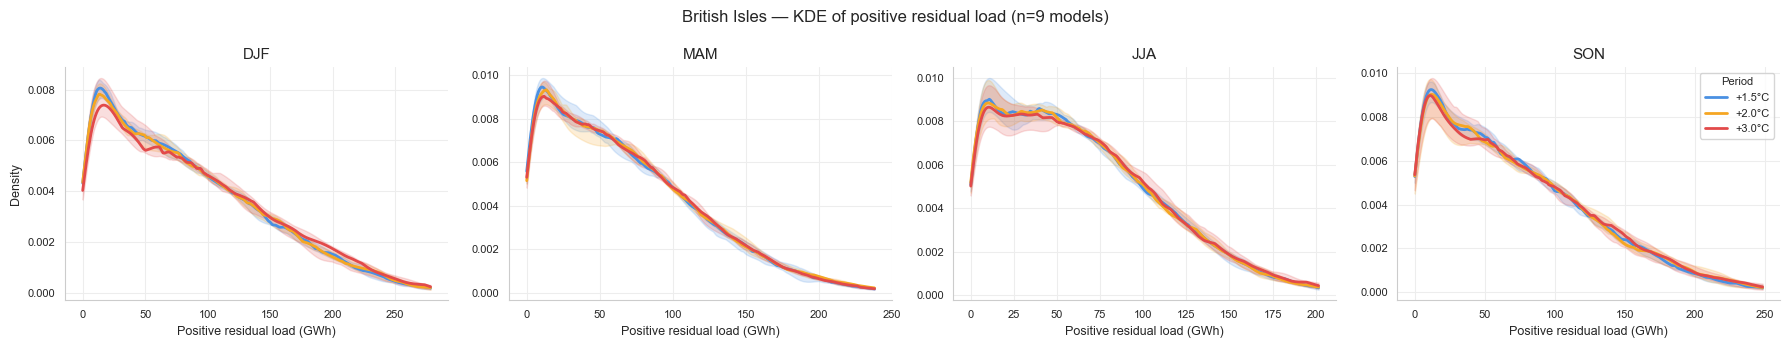

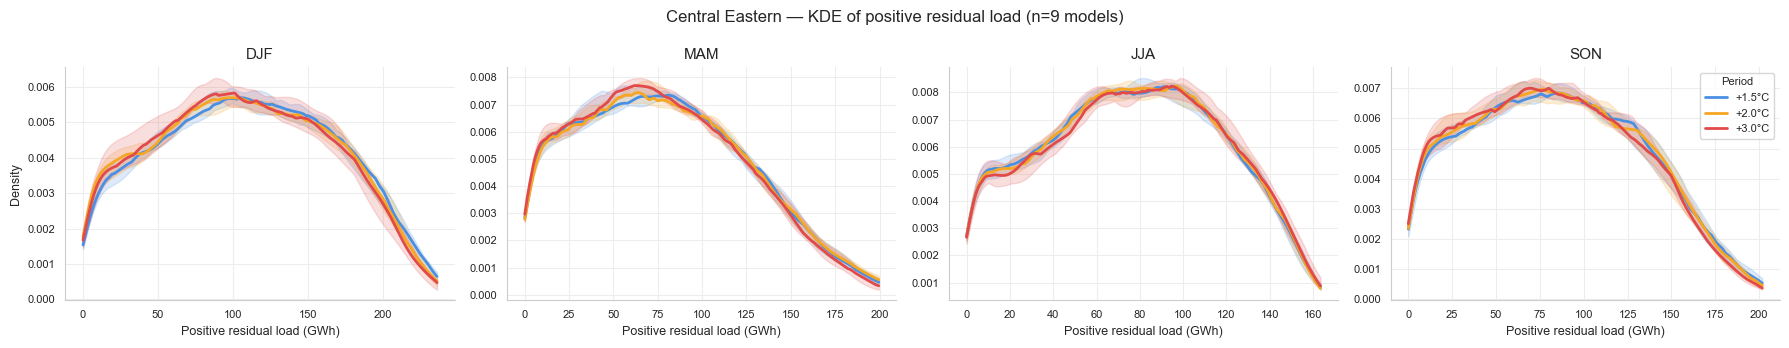

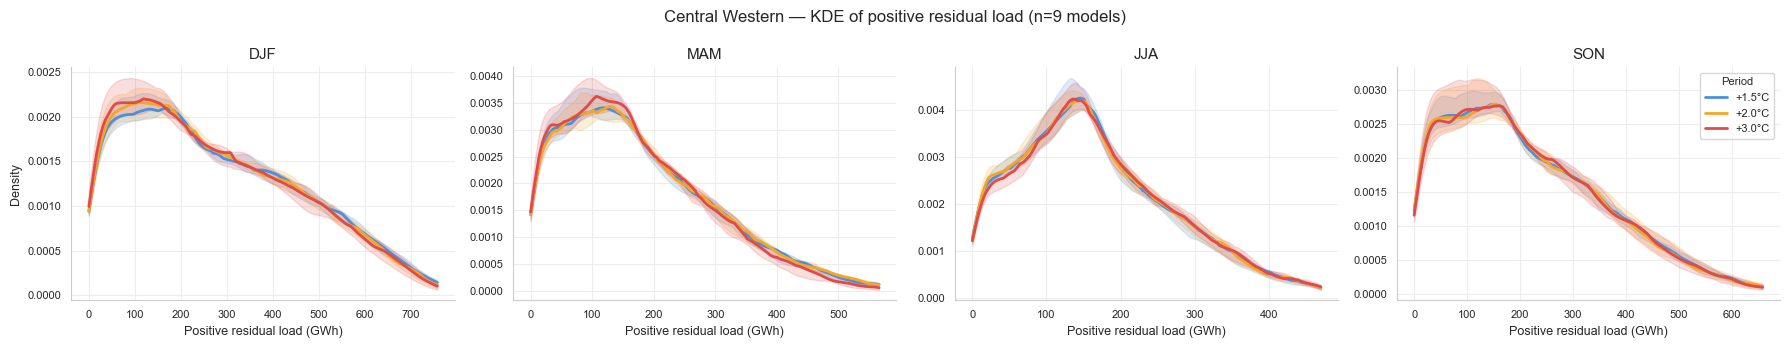

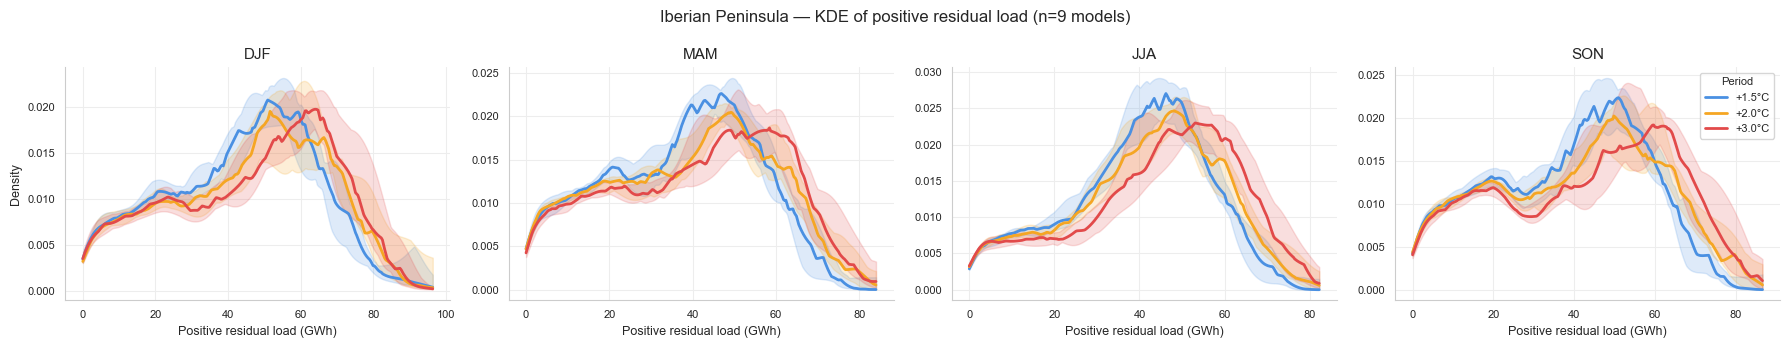

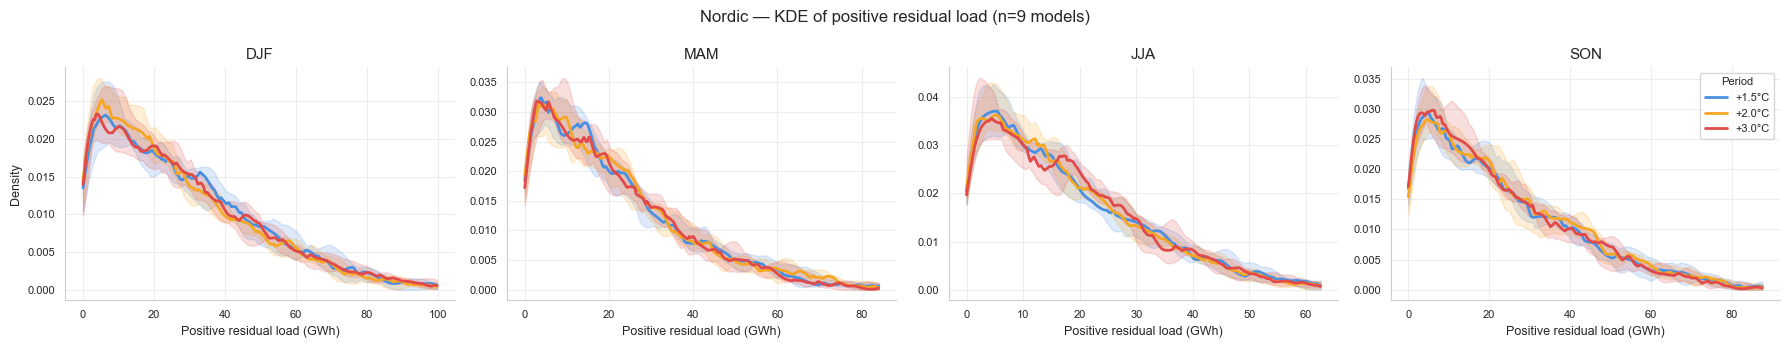

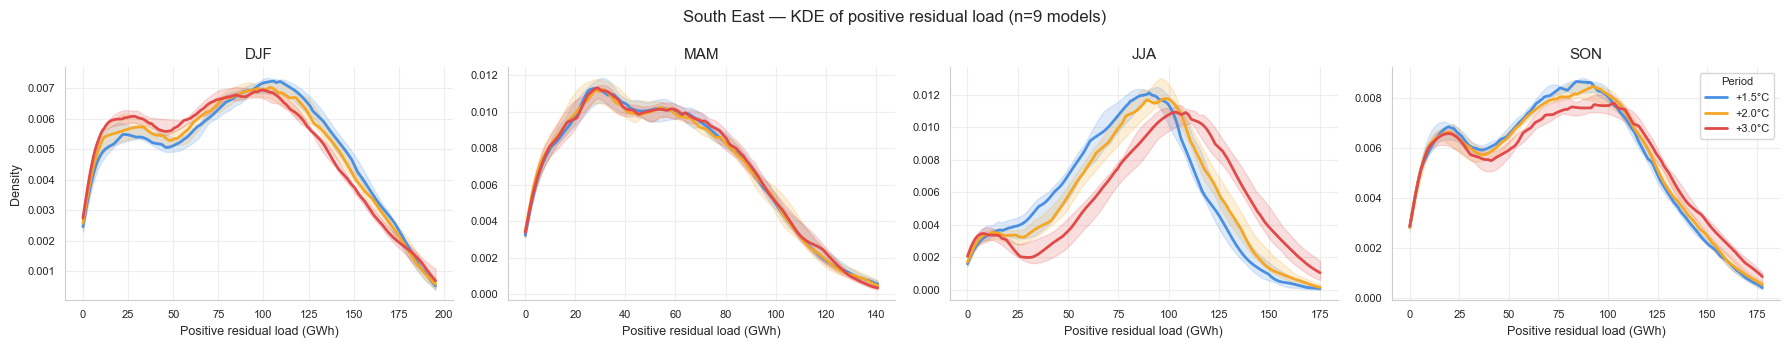

In [55]:
plot_residual_load_kde(
    ds_residual_load_zonal,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    models=models,
    season_map=season_map,
    season_order=season_order,
    threshold=0,  # None → full distribution; 0.0 → positive RL only
)

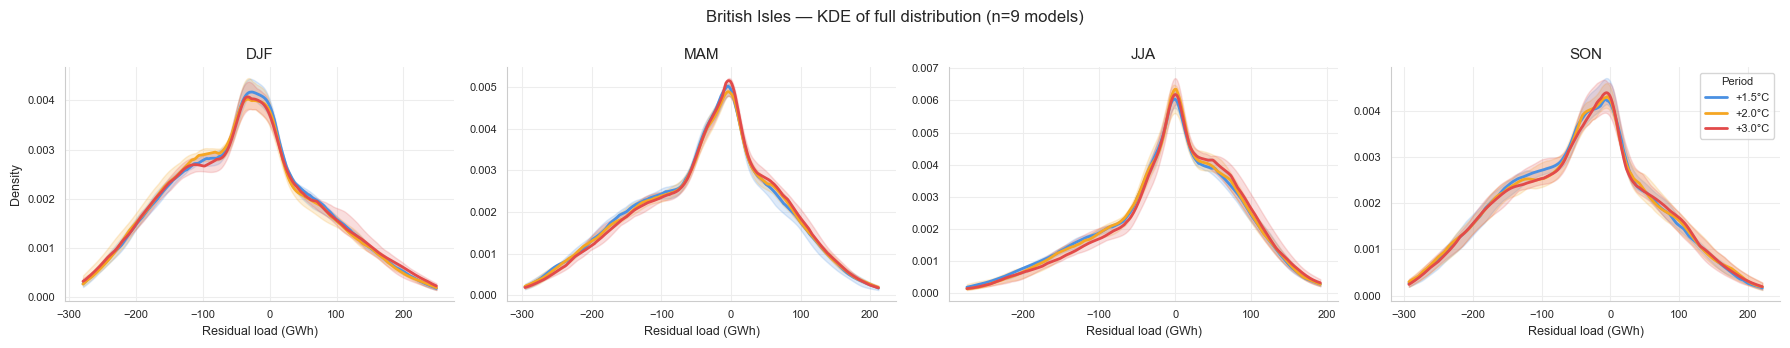

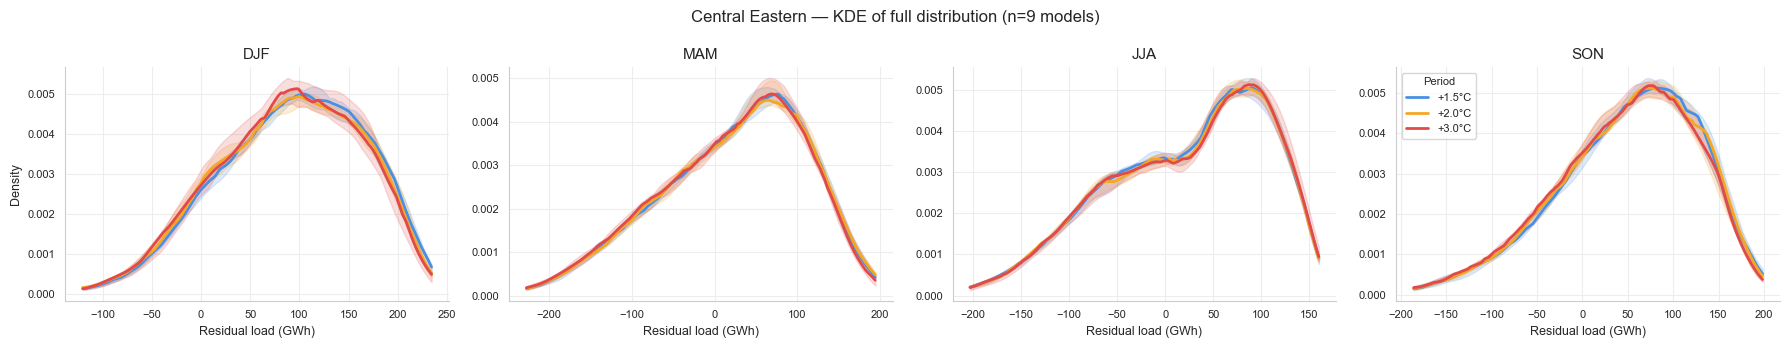

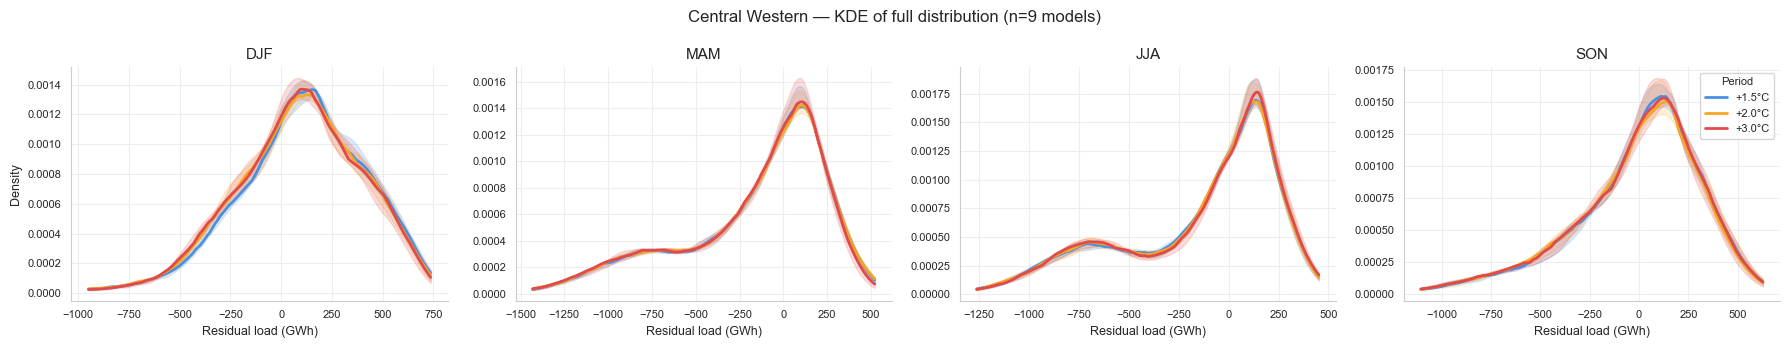

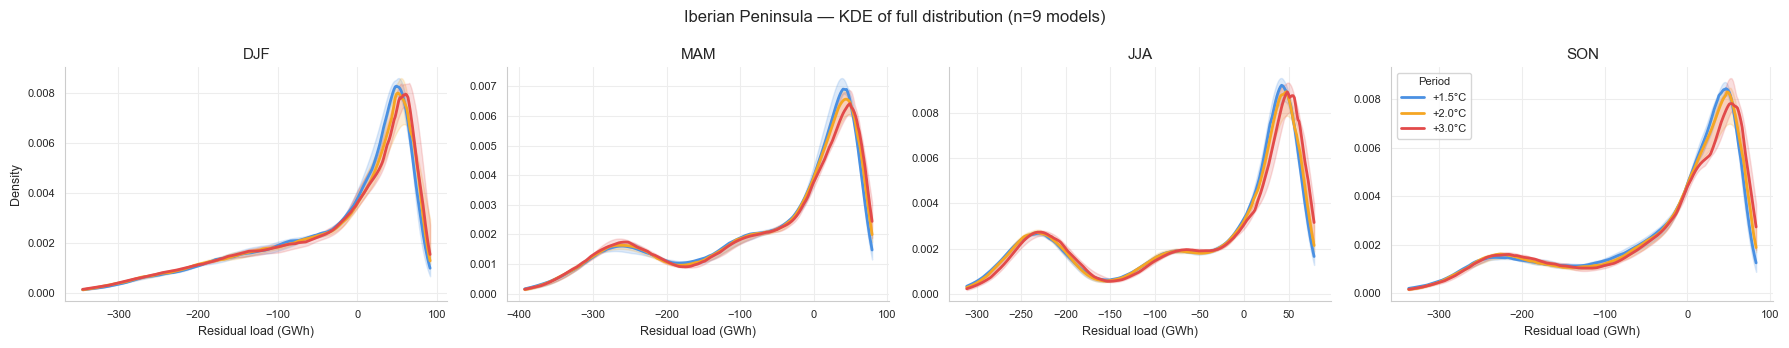

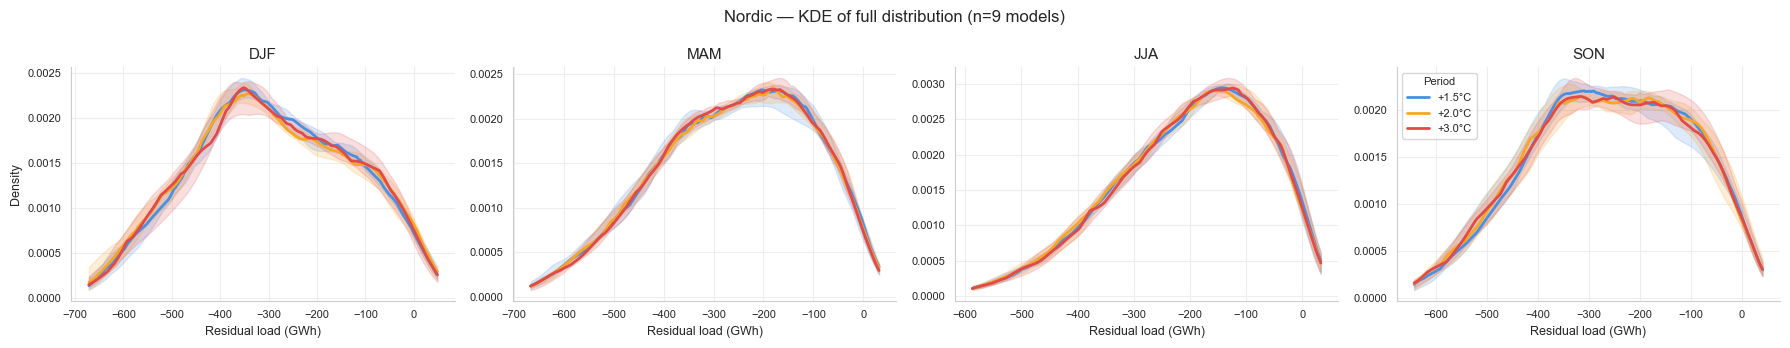

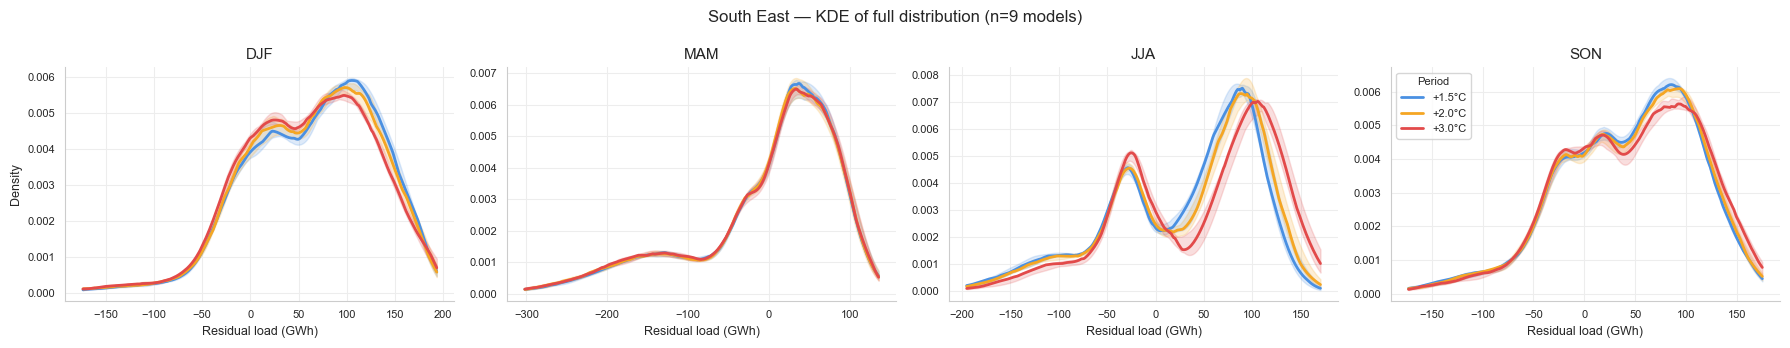

In [56]:
plot_residual_load_kde(
    ds_residual_load_zonal,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    models=models,
    season_map=season_map,
    season_order=season_order,
    threshold=None,  # None → full distribution including negative RL
)

In [72]:
_cache_rl   = {}
_cache_comp = {}
_cache_clim = {}
evt_thresholds        = {}   # {model: DataArray}
season_evt_thresholds = {}   # {model: {zone: {season: float}}}

for model in models:
    print(f"\n── {model}")

    ds_rl_m = (
        ds_residual_load_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    ds_comp_m = (
        ds_components_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    _common_time = np.intersect1d(ds_rl_m.time.values, ds_comp_m.time.values)
    ds_rl_m   = ds_rl_m.sel(time=_common_time)
    ds_comp_m = ds_comp_m.sel(time=_common_time)

    ds_clim = calculate_climatological_baseline(ds_comp_m.sel(time=slice(*REFERENCE_PERIOD)))

    t0_ref, t1_ref = REFERENCE_PERIOD
    ds_rl_ref  = ds_rl_m.sel(time=slice(t0_ref, t1_ref))
    ds_comp_ref = ds_comp_m.sel(time=slice(t0_ref, t1_ref))
    ds_met_ref  = compute_continuous_system_metrics(ds_rl_ref, ds_comp_ref, ds_clim)

    da_evt, da_evt_pct = compute_evt_thresholds_for_all_zones(ds_met_ref["residual_load"])
    evt_thresholds[model] = da_evt
    print(
        "  EVT thresholds (GW):",
        {str(z): round(float(da_evt.sel(zone=z)), 1) for z in da_evt.zone.values},
    )
    print(
        "  Percentile of full RL distribution (%):",
        {str(z): round(float(da_evt_pct.sel(zone=z)), 1) for z in da_evt_pct.zone.values},
    )

    season_evt_thresholds[model], _s_pct = calibrate_seasonal_evt_thresholds(
        ds_rl_ref, zones, season_order, season_months
    )
    print("  Seasonal EVT percentiles (%):")
    for zone in zones:
        row = "    " + str(zone) + ": " + "  ".join(
            f"{s}={_s_pct[str(zone)][s]:.1f}" for s in season_order
        )
        print(row)

    _cache_rl[model]   = ds_rl_m
    _cache_comp[model] = ds_comp_m
    _cache_clim[model] = ds_clim

print("\n✓ Setup complete for all models")


── CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
  EVT thresholds (GW): {'British_Isles': 170.8, 'Central_Eastern': 223.2, 'Central_Western': 659.7, 'Iberian_Peninsula': 59.1, 'Nordic': 53.3, 'South_East': 166.3}
  Percentile of full RL distribution (%): {'British_Isles': 98.2, 'Central_Eastern': 99.6, 'Central_Western': 99.5, 'Iberian_Peninsula': 92.5, 'Nordic': 99.8, 'South_East': 98.6}
  Seasonal EVT percentiles (%):
    British_Isles: DJF=95.1  MAM=94.8  JJA=93.9  SON=98.6
    Central_Eastern: DJF=98.5  MAM=99.3  JJA=96.4  SON=92.3
    Central_Western: DJF=99.3  MAM=93.0  JJA=92.6  SON=91.2
    Iberian_Peninsula: DJF=92.1  MAM=93.4  JJA=93.4  SON=92.1
    Nordic: DJF=99.8  MAM=99.7  JJA=99.7  SON=99.6
    South_East: DJF=95.4  MAM=90.7  JJA=91.1  SON=99.4

── CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1
  EVT thresholds (GW): {'British_Isles': 132.7, 'Central_Eastern': 145.5, 'Central_Western': 386.4, 'Iberian_Peninsula': 58.3, 'Nordic': 41.1, 'South_East': 171.5}
  Percentile of full RL dis

# Seasonal Analysis

## Seasonal-conditional EVT metrics

Computes event frequency, duration, severity, PCIT, and driver attribution
for each (zone, season) using **season-specific thresholds** calibrated from
the reference period. Events are constrained to each season (cross-season
connections are blocked). This answers: *how does each season's own extreme
tail evolve with warming?*

In [73]:
all_rows = []
for model in models:
    resolved = {
        k: v for k, v in resolve_model_periods(period_defs, model).items()
        if v is not None
    }
    for period_name, (t0, t1) in resolved.items():
        ds_rl_p   = _cache_rl[model].sel(time=slice(t0, t1))
        ds_comp_p = _cache_comp[model].sel(time=slice(t0, t1))
        ds_met_p  = compute_continuous_system_metrics(ds_rl_p, ds_comp_p, _cache_clim[model])
        all_rows += compute_seasonal_evt_metrics(
            ds_rl_p, ds_met_p,
            season_order, season_months,
            season_evt_thresholds[model],
            model, period_name, zones,
        )

df_seasonal_evt = pd.DataFrame(all_rows)
print(f"df_seasonal_evt: {df_seasonal_evt.shape[0]} rows × {df_seasonal_evt.shape[1]} columns")
df_seasonal_evt.groupby(["zone", "season", "Period"])["Frequency"].median().unstack("Period").round(0)


df_seasonal_evt: 648 rows × 29 columns


Period                    +1.5°C  +2.0°C  +3.0°C
zone              season                        
British_Isles     DJF      294.0   257.0   273.0
                  JJA      640.0   665.0   685.0
                  MAM      345.0   379.0   383.0
                  SON      257.0   260.0   284.0
Central_Eastern   DJF       89.0    65.0    55.0
                  JJA      297.0   302.0   312.0
                  MAM      433.0   408.0   399.0
                  SON      126.0   120.0   105.0
Central_Western   DJF      255.0   214.0   196.0
                  JJA      922.0   950.0   954.0
                  MAM      536.0   506.0   496.0
                  SON      554.0   498.0   498.0
Iberian_Peninsula DJF      368.0   470.0   512.0
                  JJA      356.0   492.0   708.0
                  MAM      311.0   488.0   590.0
                  SON      128.0   273.0   209.0
Nordic            DJF       27.0    25.0    24.0
                  JJA       43.0    45.0    40.0
                  MAM       30.0    26.0    23.0
                  SON       36.0    40.0    33.0
South_East        DJF      269.0   261.0   301.0
                  JJA     1132.0  1319.0  1719.0
                  MAM      698.0   758.0   662.0
                  SON      366.0   408.0   453.0

In [74]:
# Ensemble-median season-specific thresholds vs common annual threshold
print("Season-specific EVT thresholds — ensemble median (GWh)\n")
header = f"{'Zone':<22}" + "".join(f"{s:>8}" for s in season_order) + f"{'Annual':>10}"
print(header)
print("-" * len(header))
for zone in zones:
    annual_med = np.median([float(evt_thresholds[m].sel(zone=zone)) for m in models])
    row = f"{str(zone):<22}"
    for season in season_order:
        s_med = np.median([season_evt_thresholds[m][str(zone)][season] for m in models])
        row += f"{s_med:>8.1f}"
    row += f"{annual_med:>10.1f}"
    print(row)


Season-specific EVT thresholds — ensemble median (GWh)

Zone                       DJF     MAM     JJA     SON    Annual
----------------------------------------------------------------
British_Isles            162.6   141.4   114.9   149.6     153.0
Central_Eastern          223.8   137.4   143.4   175.6     218.9
Central_Western          644.6   323.8   290.0   411.2     600.9
Iberian_Peninsula         70.8    58.6    57.7    74.5      69.3
Nordic                    54.8    42.5    32.5    42.7      44.0
South_East               172.9    92.3   106.5   146.6     168.3


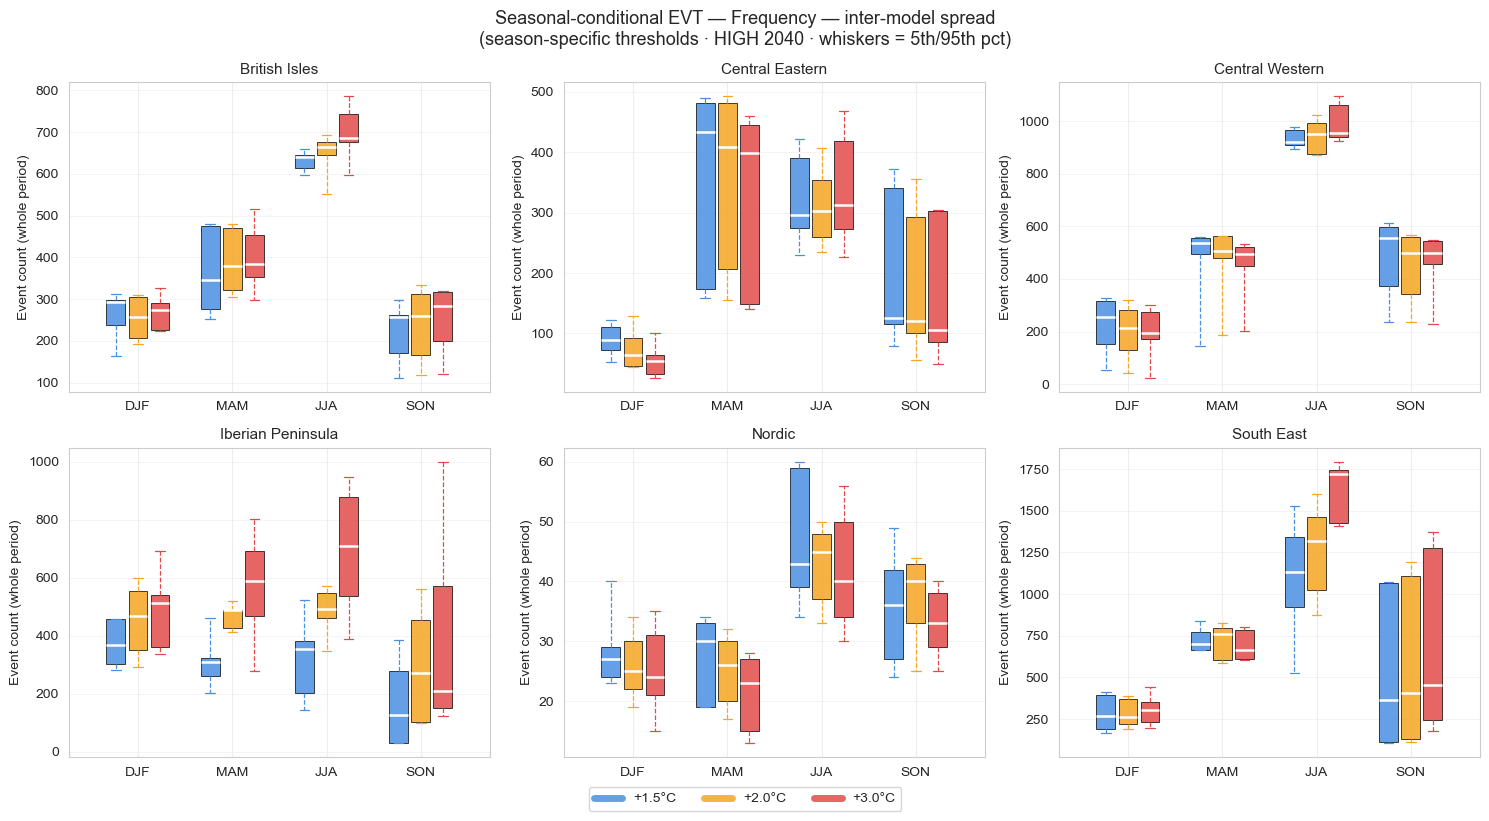

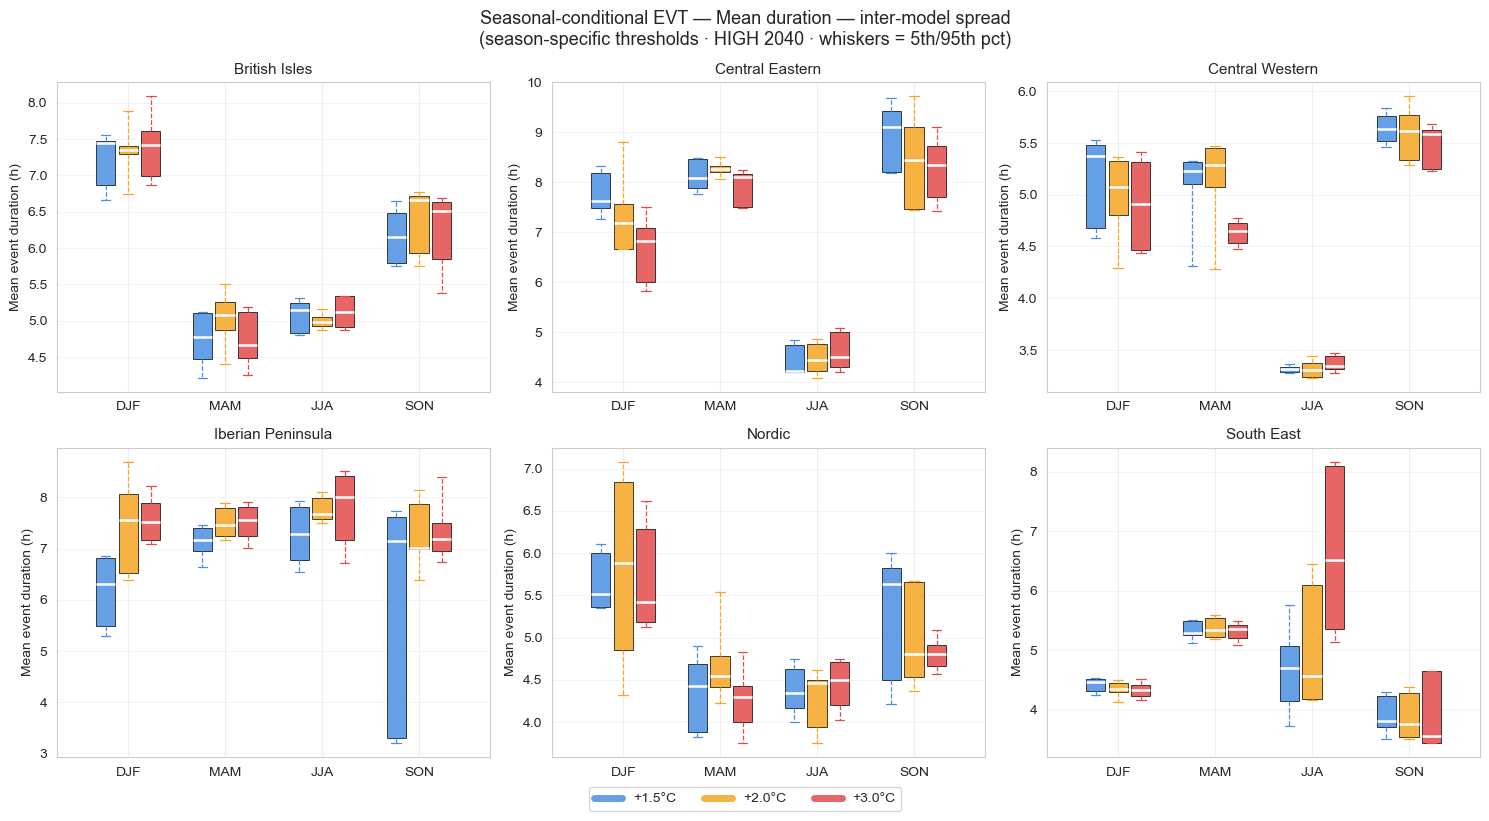

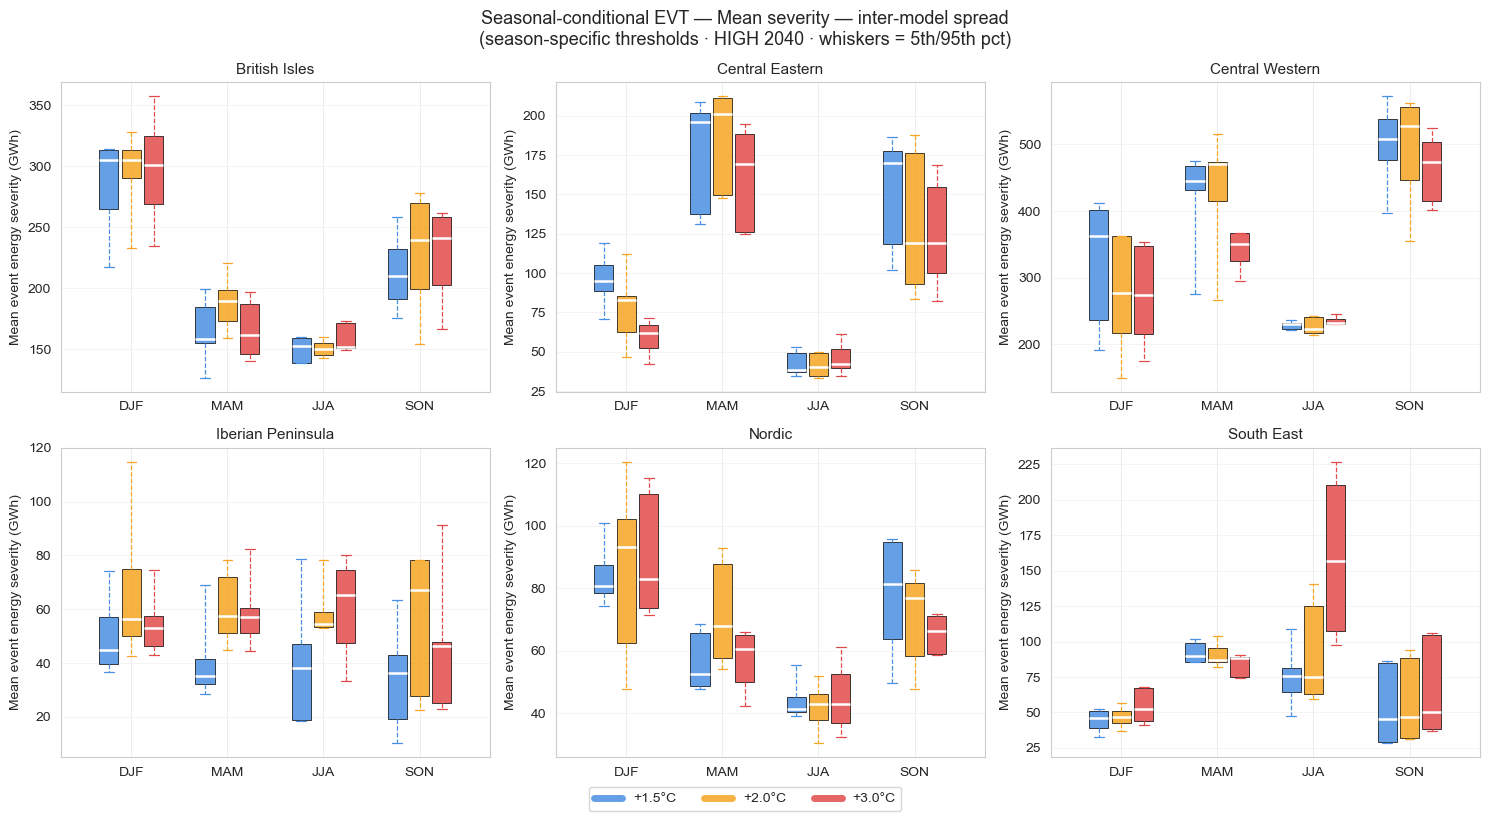

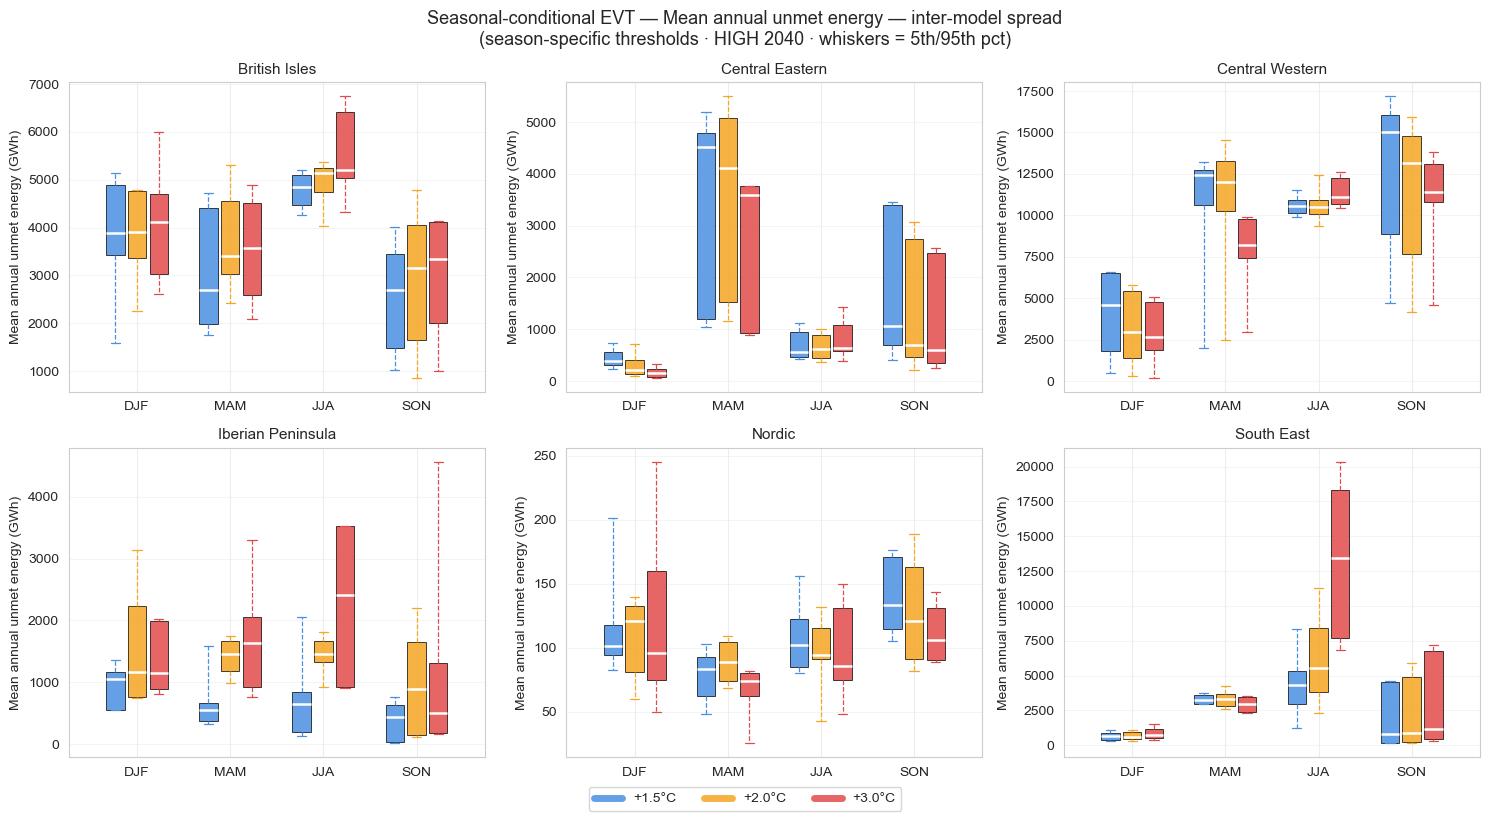

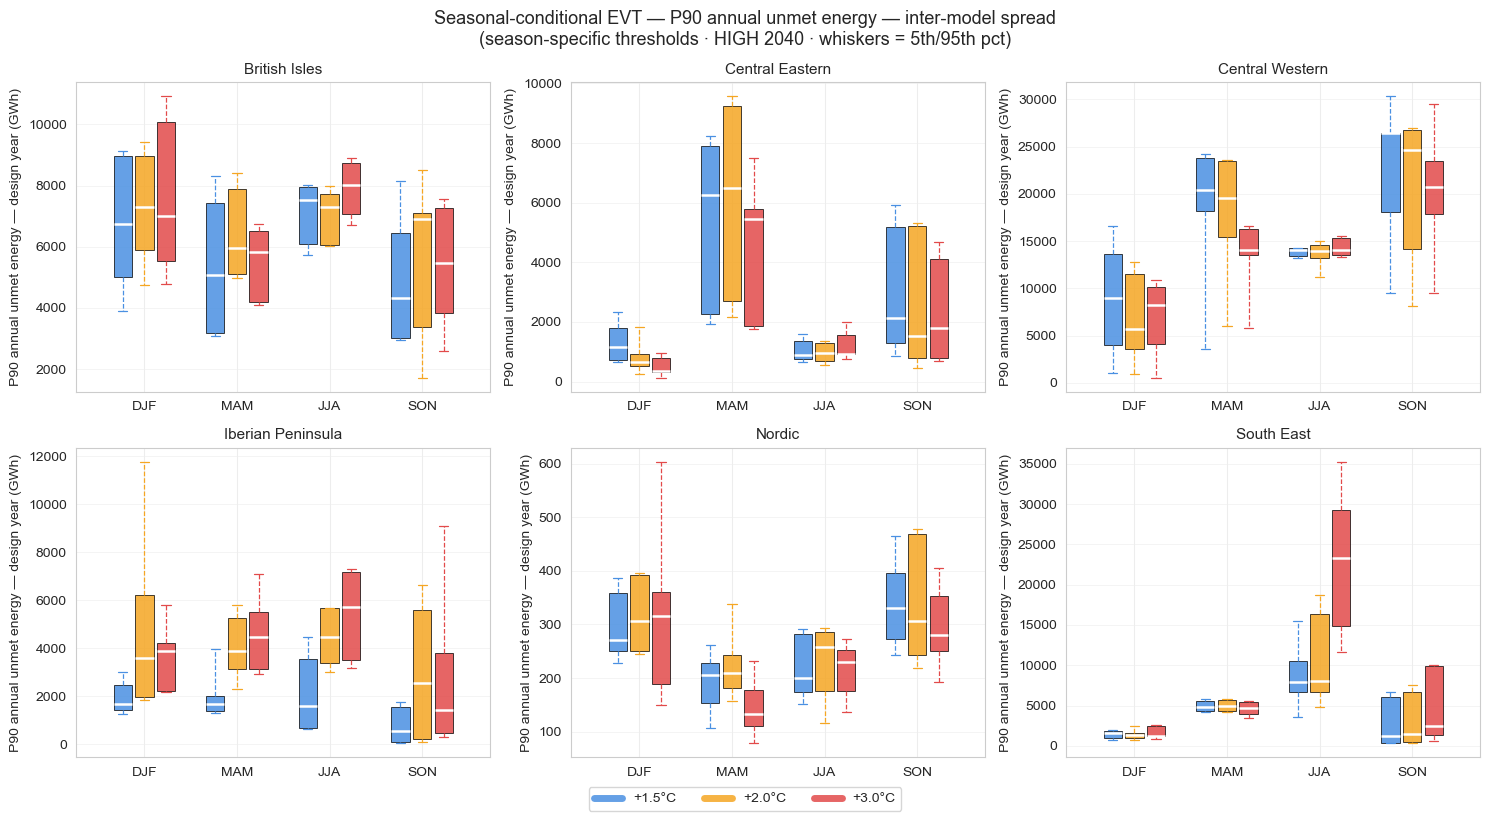

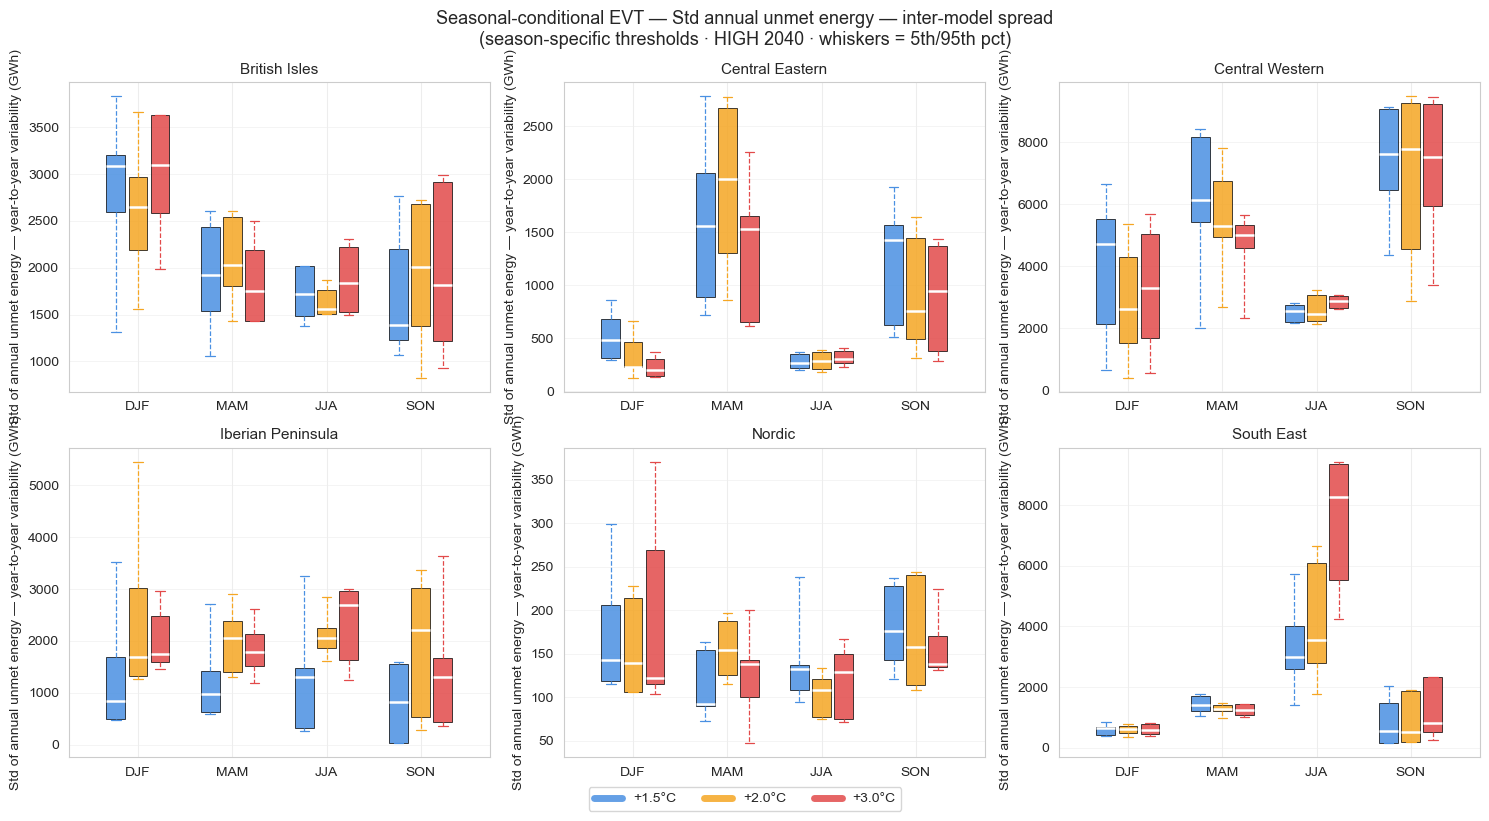

In [75]:
baseline_metrics = [
    ("Frequency",                        "Event count (whole period)",      "Frequency"),
    ("Avg_Duration_Hours",               "Mean event duration (h)",         "Mean duration"),
    ("Avg_Energy_Severity_GWh",          "Mean event energy severity (GWh)", "Mean severity"),
    ("Total_Annual_Energy_Severity_GWh", "Mean annual unmet energy (GWh)", "Mean annual unmet energy"),
    ("P90_Annual_Energy_Severity_GWh",   "P90 annual unmet energy — design year (GWh)", "P90 annual unmet energy"),
    ("Std_Annual_Energy_Severity_GWh",   "Std of annual unmet energy — year-to-year variability (GWh)", "Std annual unmet energy"),
]

plot_seasonal_conditional_metrics(
    df_seasonal_evt,
    metrics=baseline_metrics,
    zones=zones,
    period_defs=period_defs,
    season_order=season_order,
    period_colors=period_colors,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)


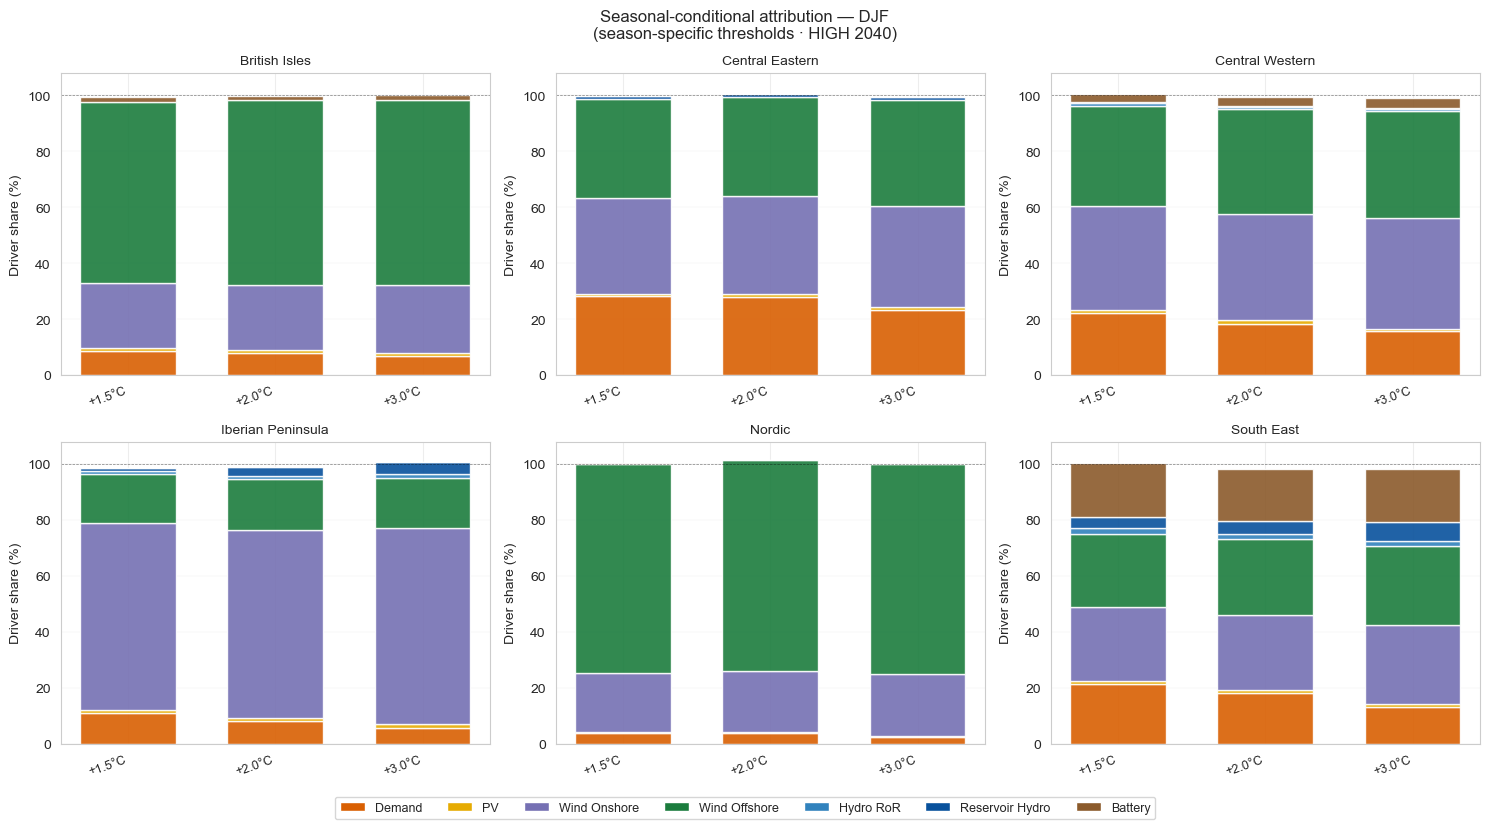

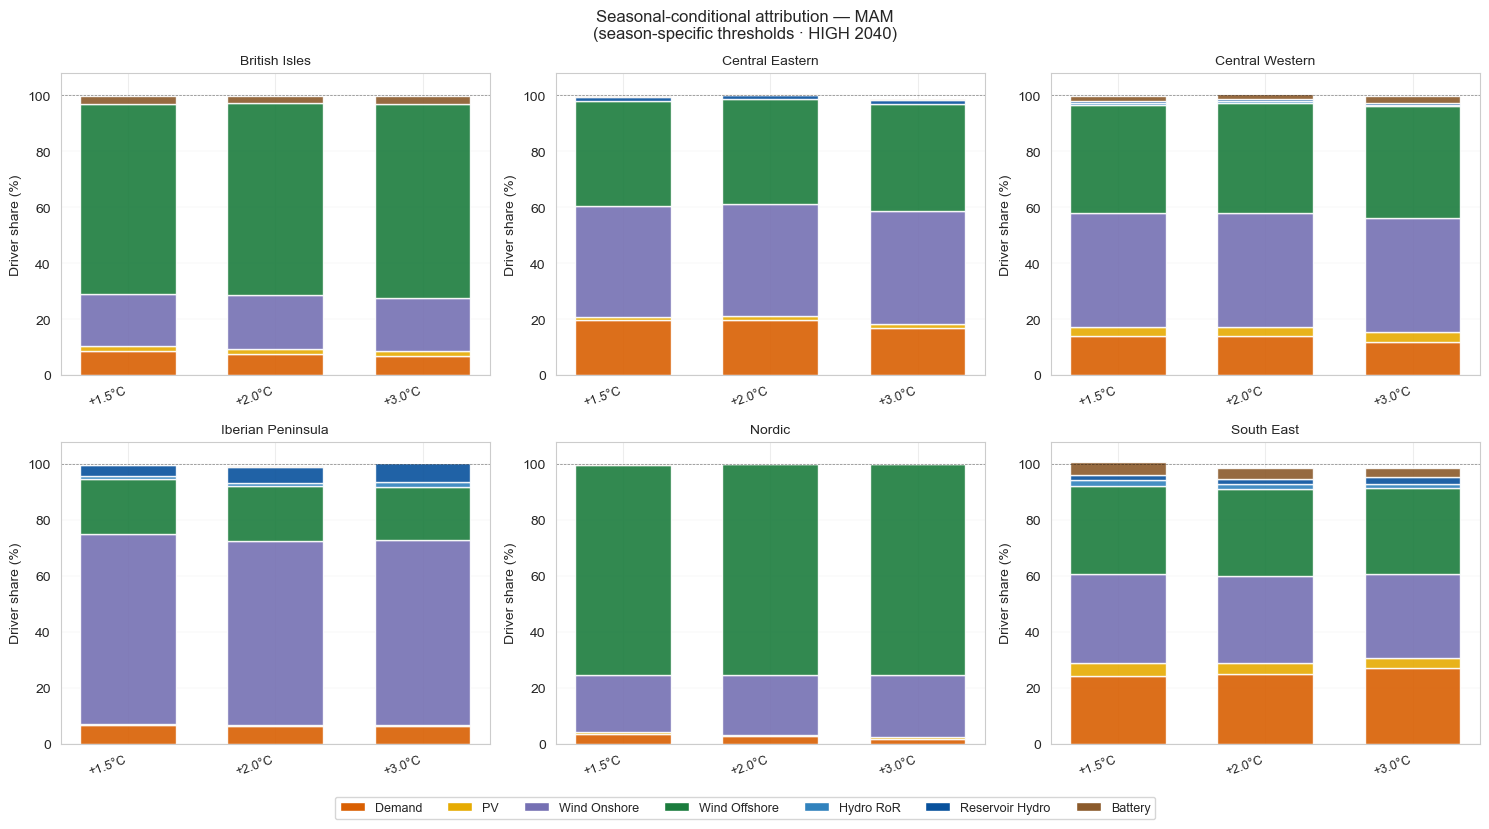

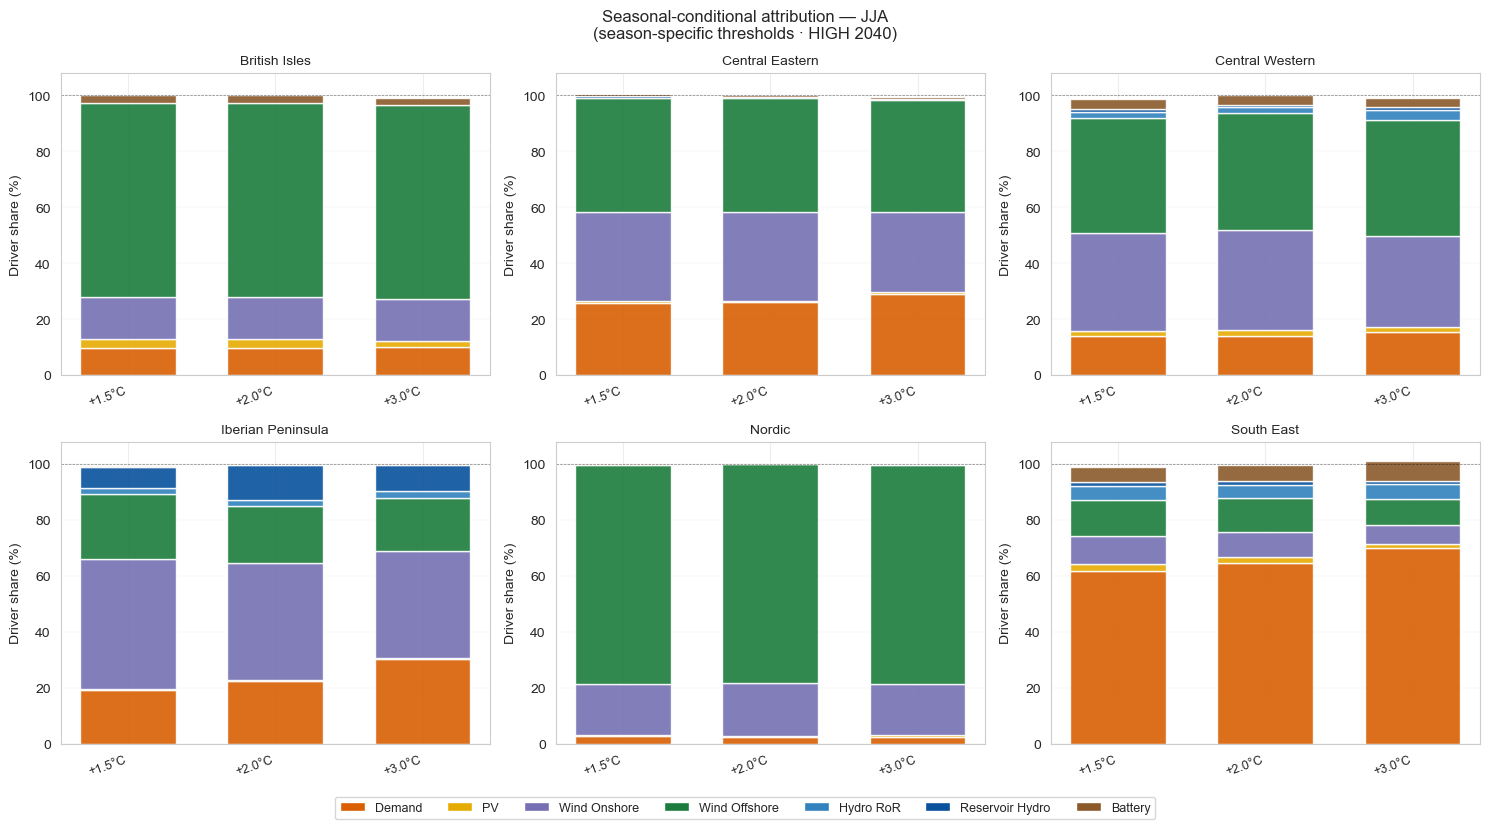

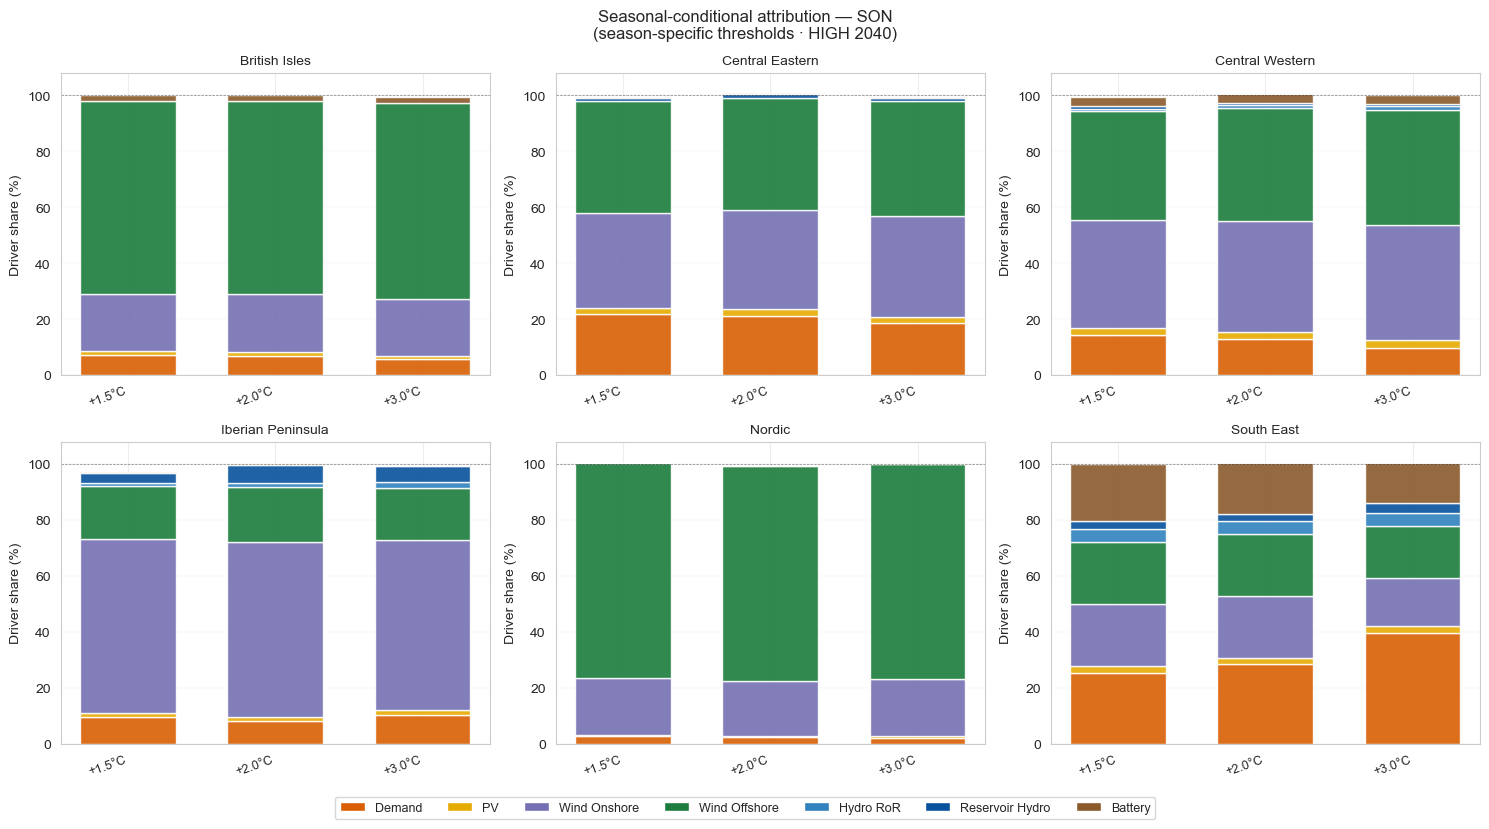

In [76]:
plot_seasonal_attribution(
    df_seasonal_evt,
    zones=zones,
    season_order=season_order,
    period_defs=period_defs,
    driver_cols=driver_cols,
    driver_palette=driver_palette,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)


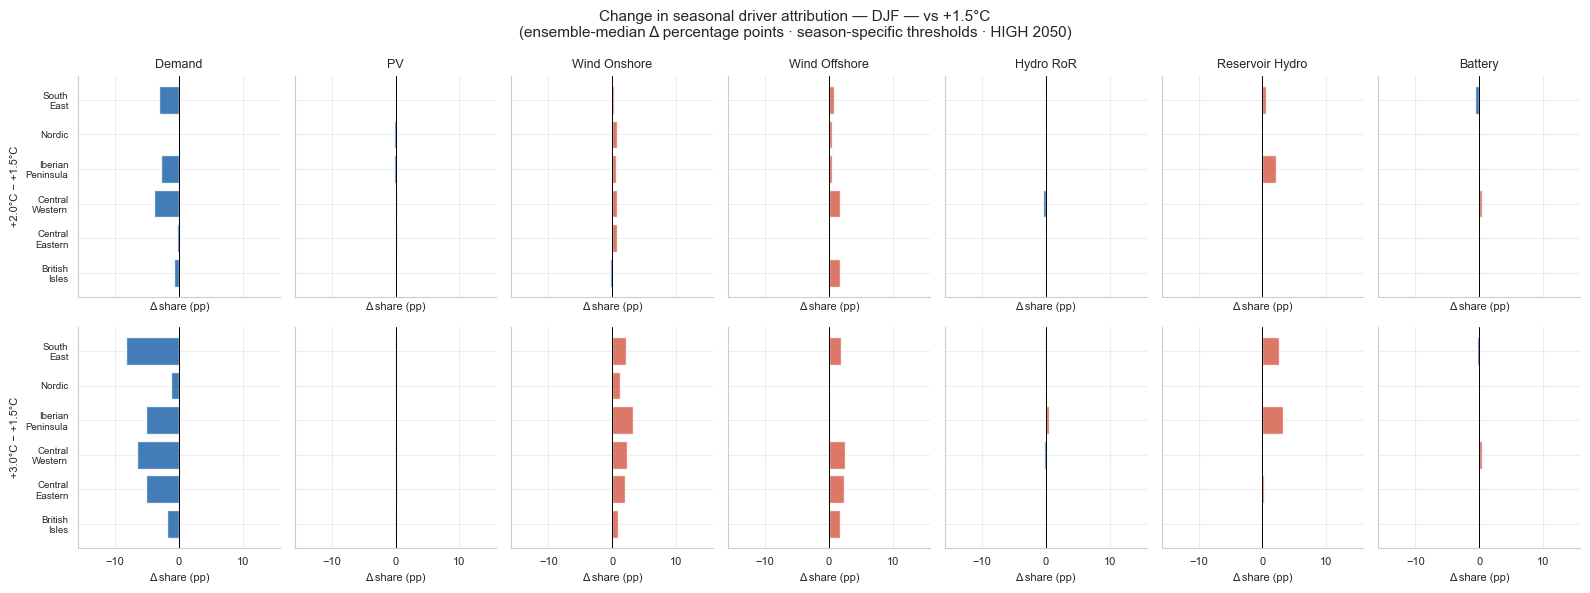

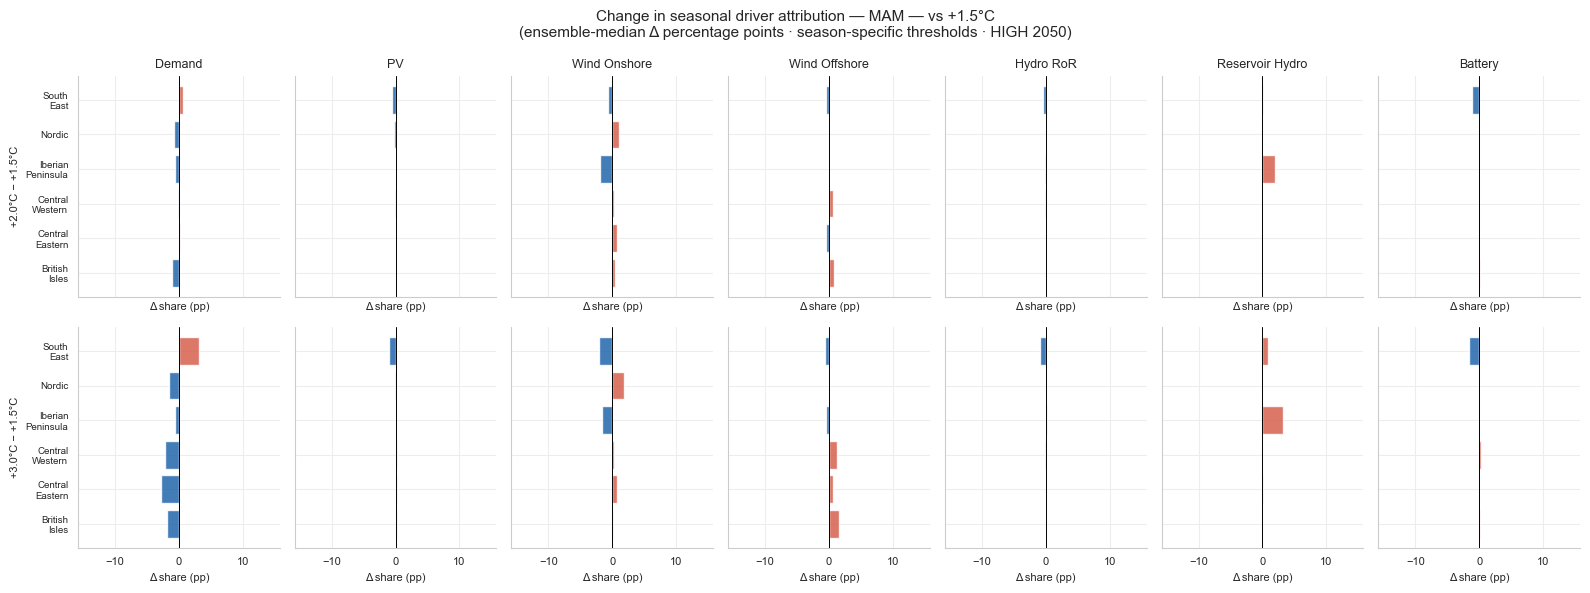

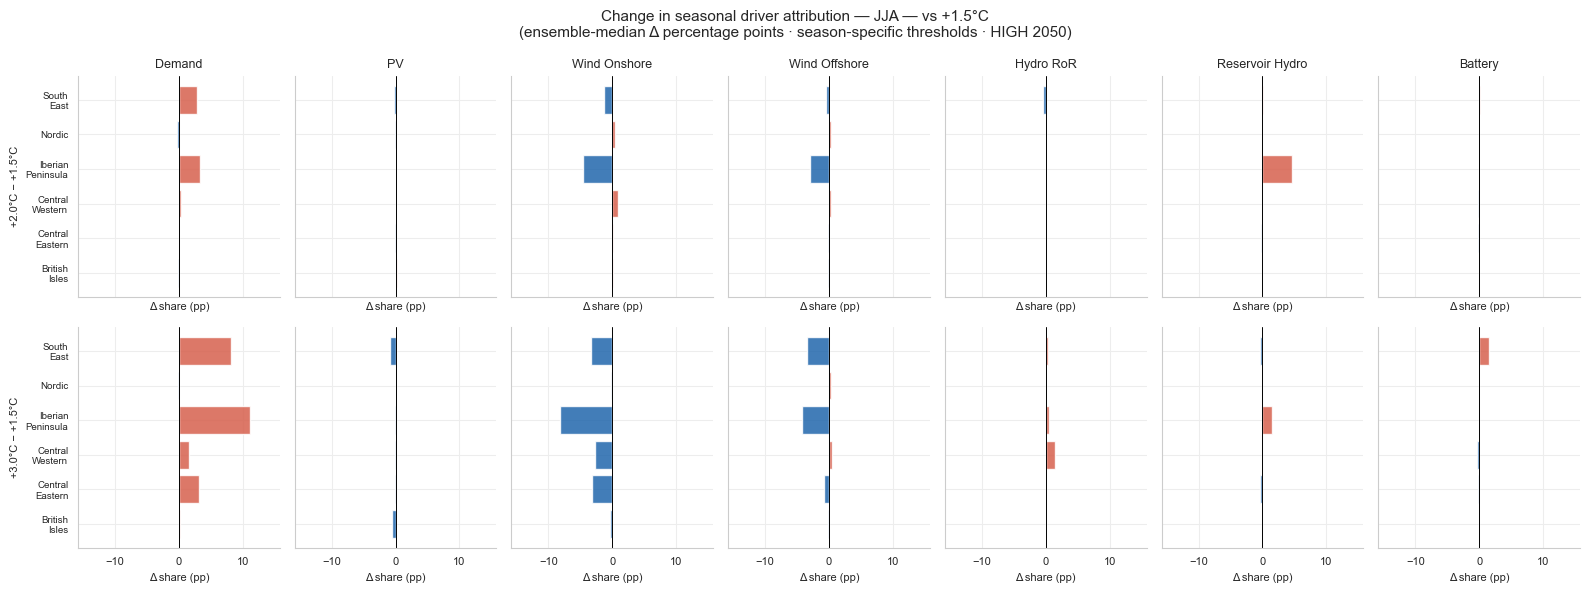

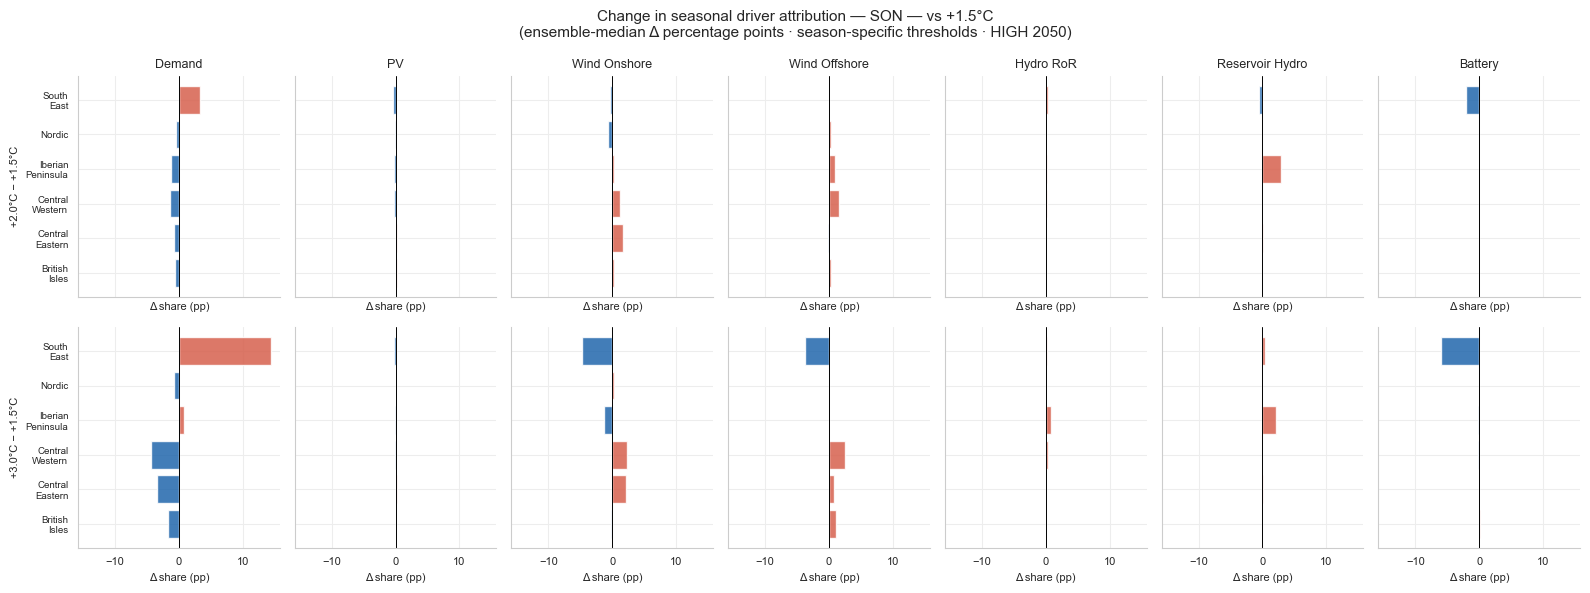

In [77]:
plot_seasonal_attribution_change(
    df_seasonal_evt,
    zones=zones,
    season_order=season_order,
    period_defs=period_defs,
    driver_cols=driver_cols,
    reference_period_name=None,  # defaults to first period
    supply_scenario=supply_scenario,
    supply_year=demand_year,
    share_x_across_seasons=True
)

## Seasonal driver anomaly distributions

Signed GWh anomaly per component during EVT events, broken down by season.

- **Per-period figures**: one figure per warming level, `x = Component, hue = Season` — shows how each driver's contribution varies across seasons within a given warming level.
- **Per-season figures**: one figure per season, `x = Component, hue = Period` — shows how the warming level shifts each driver's anomaly within that season.

Sign convention: demand anomaly positive (excess demand above baseline); generation and flexibility anomalies negative (shortfall / under-dispatch below baseline).

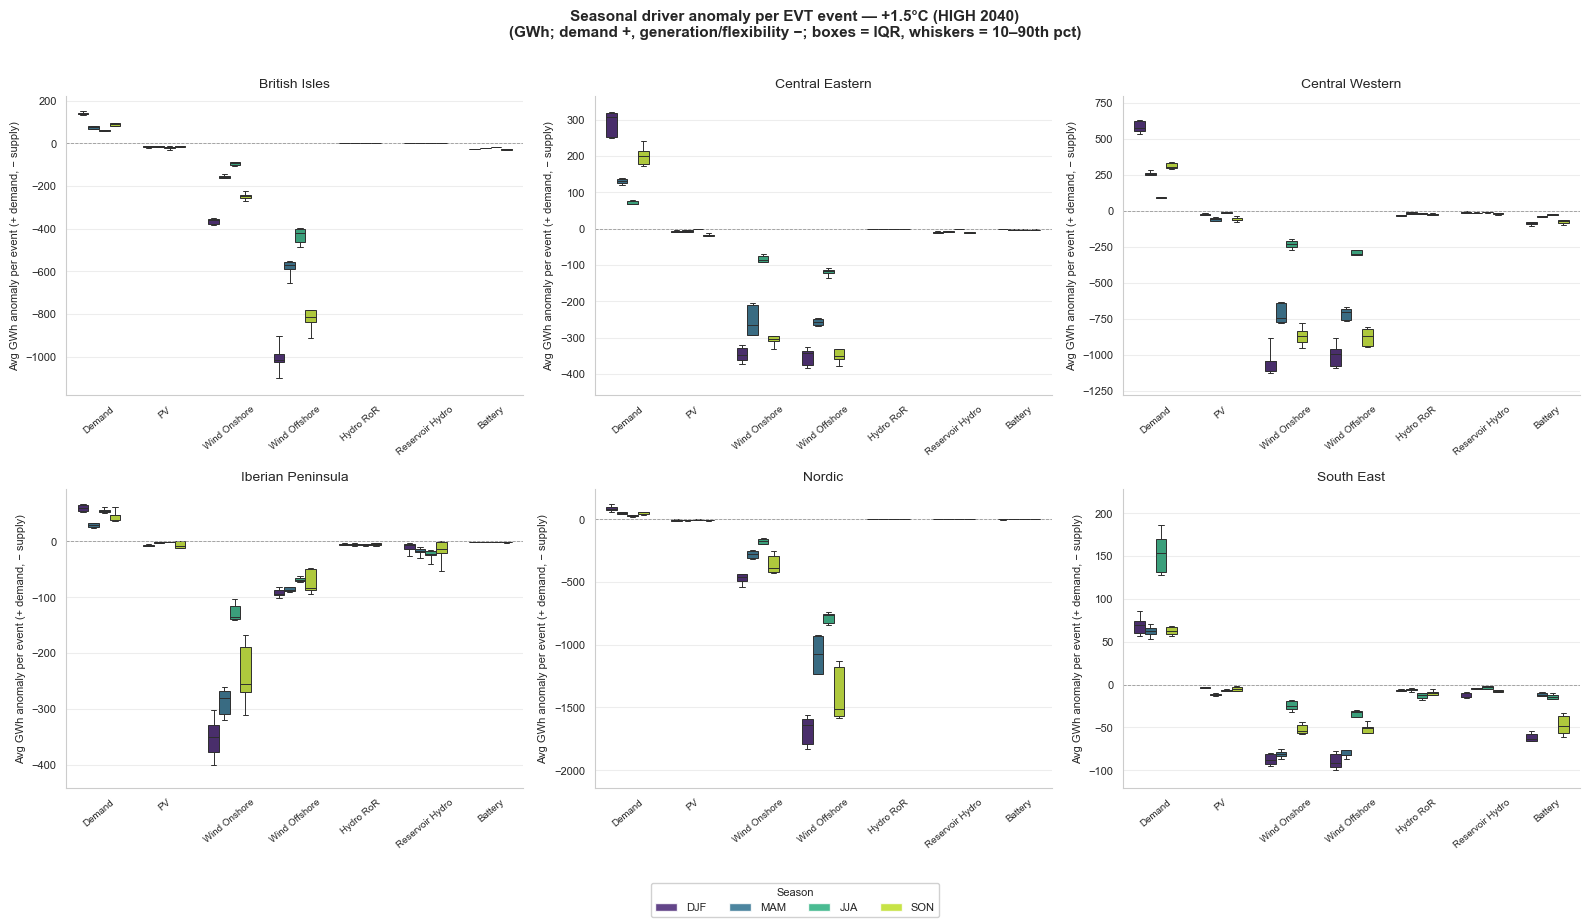

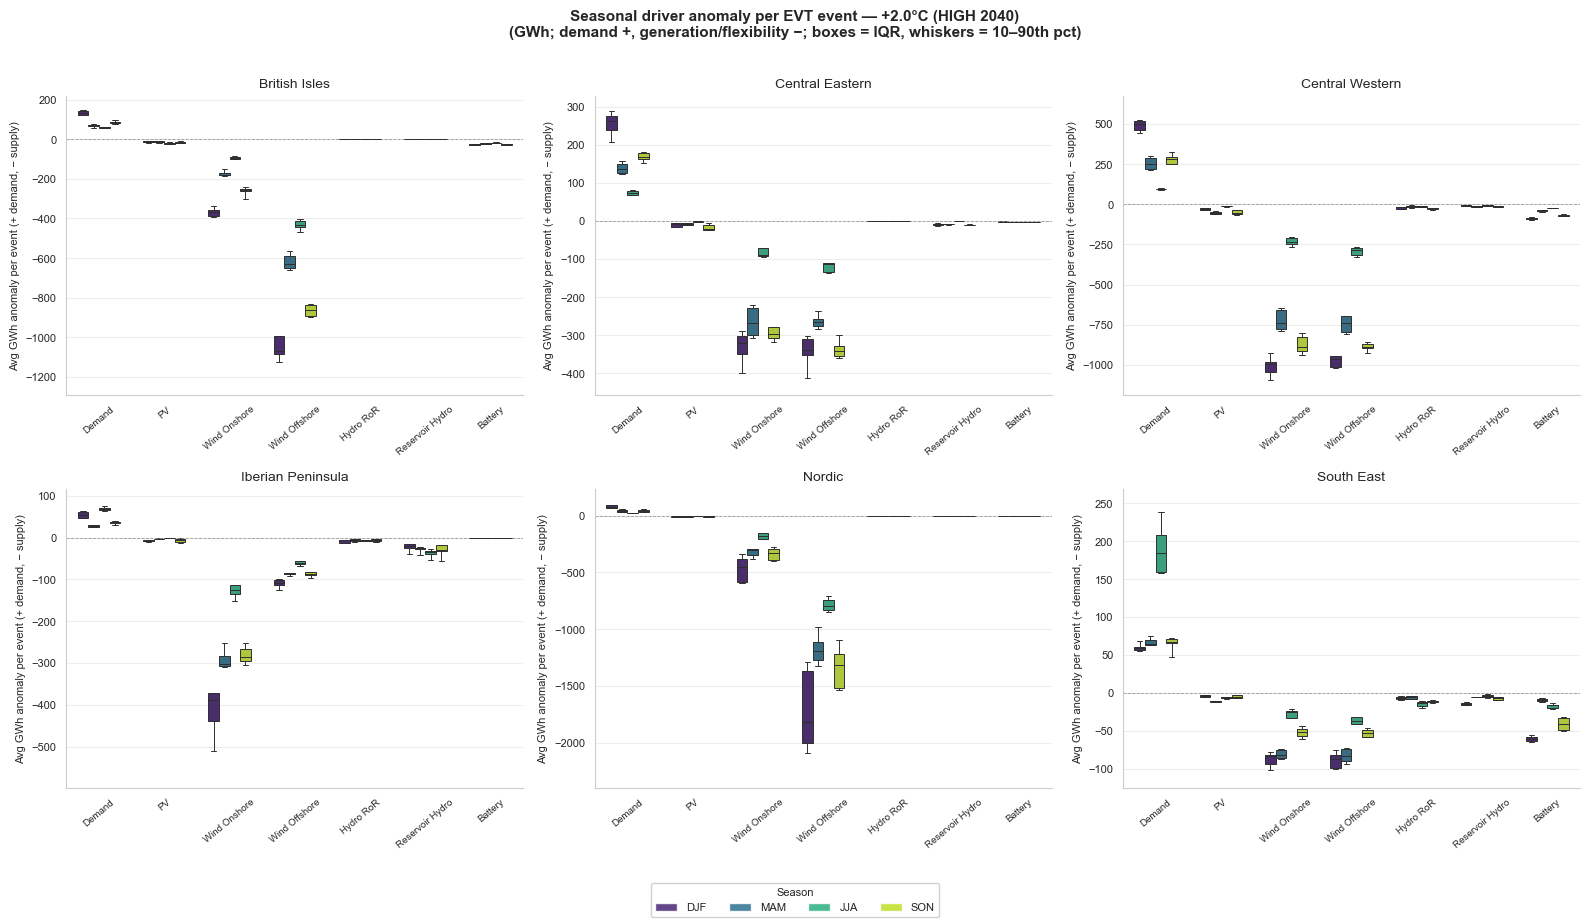

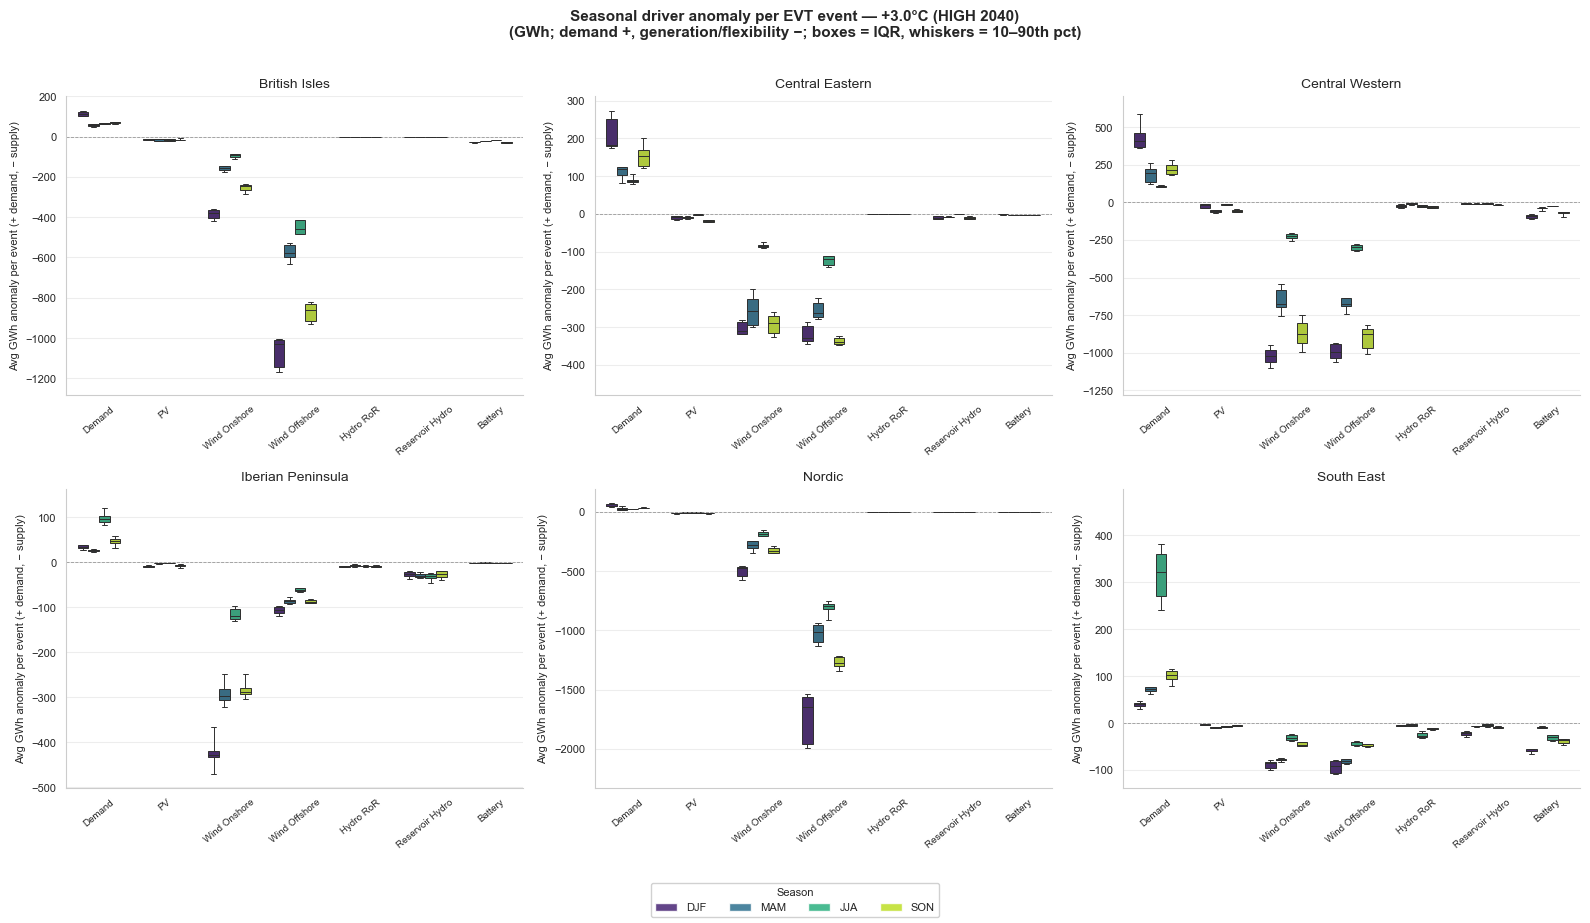

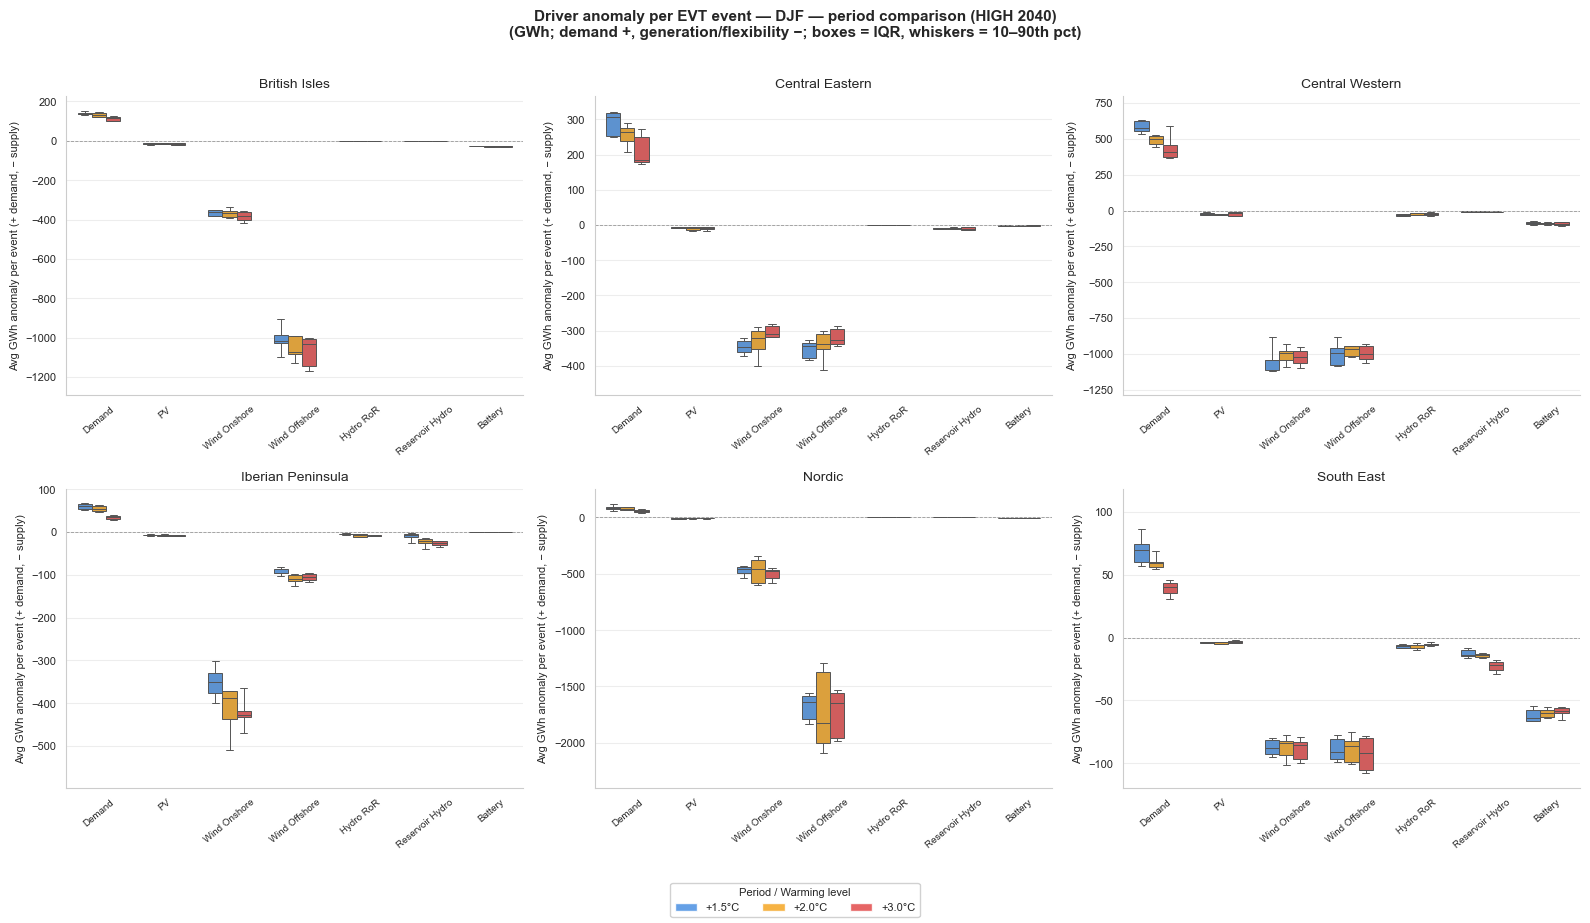

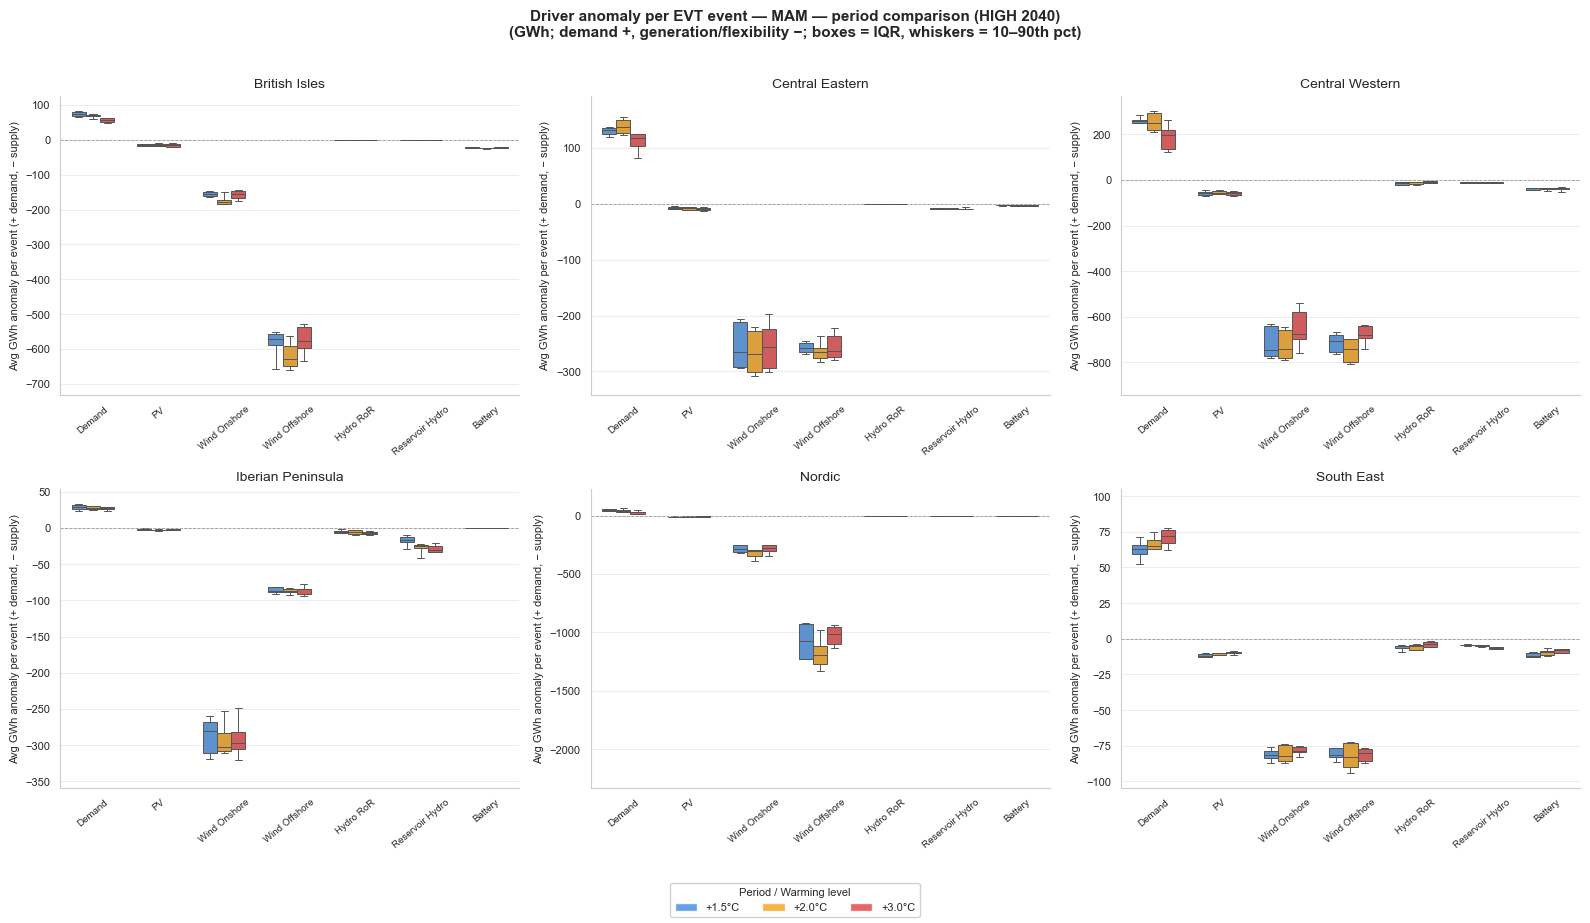

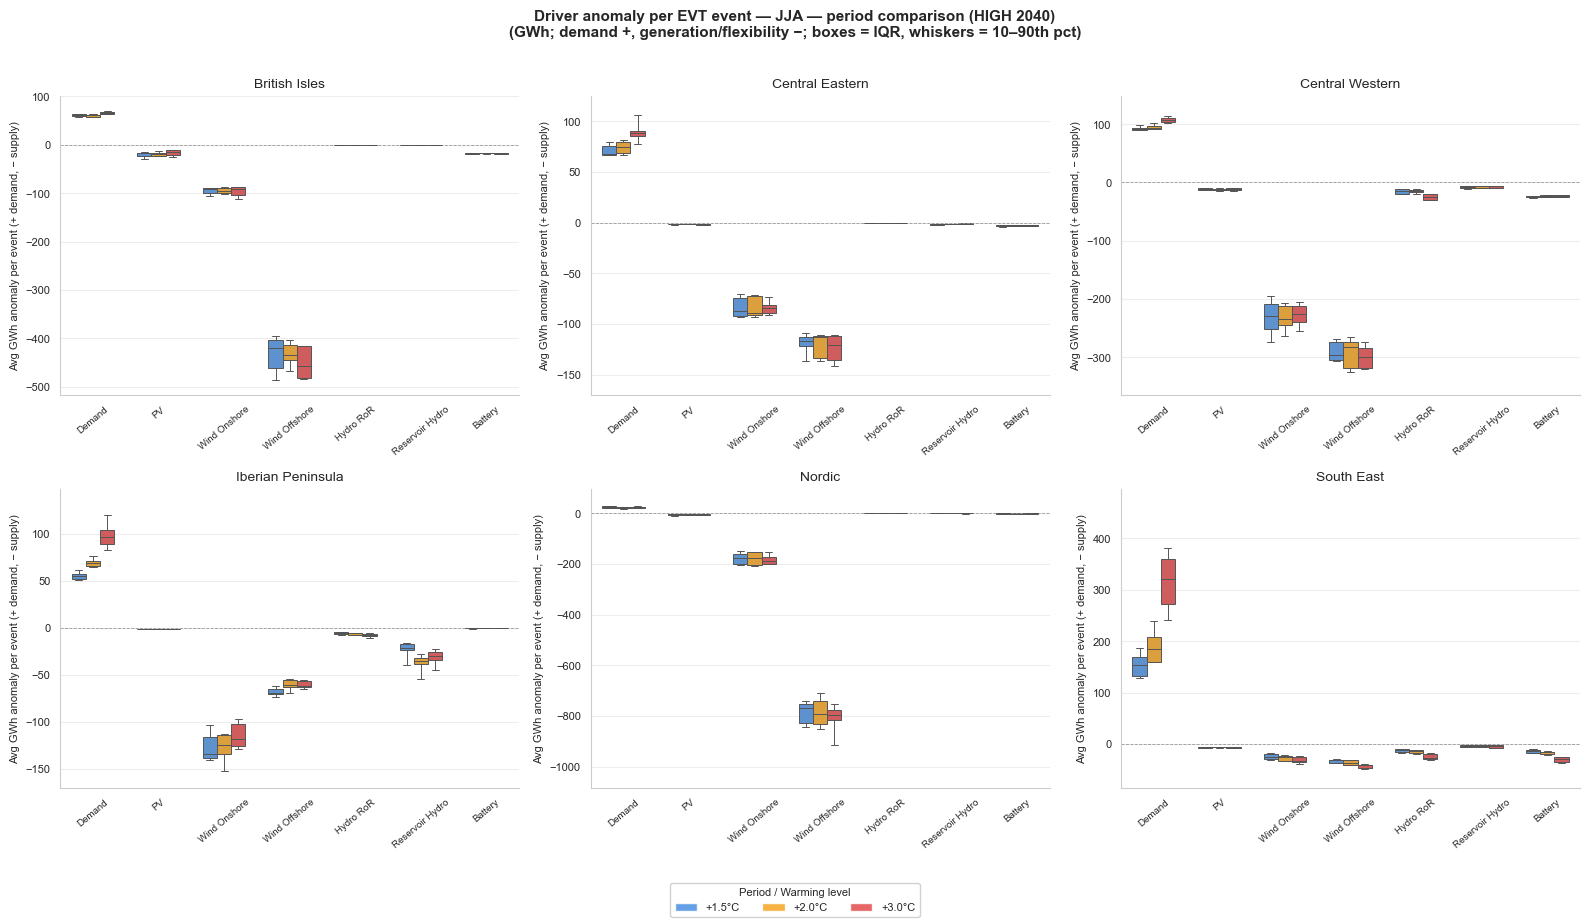

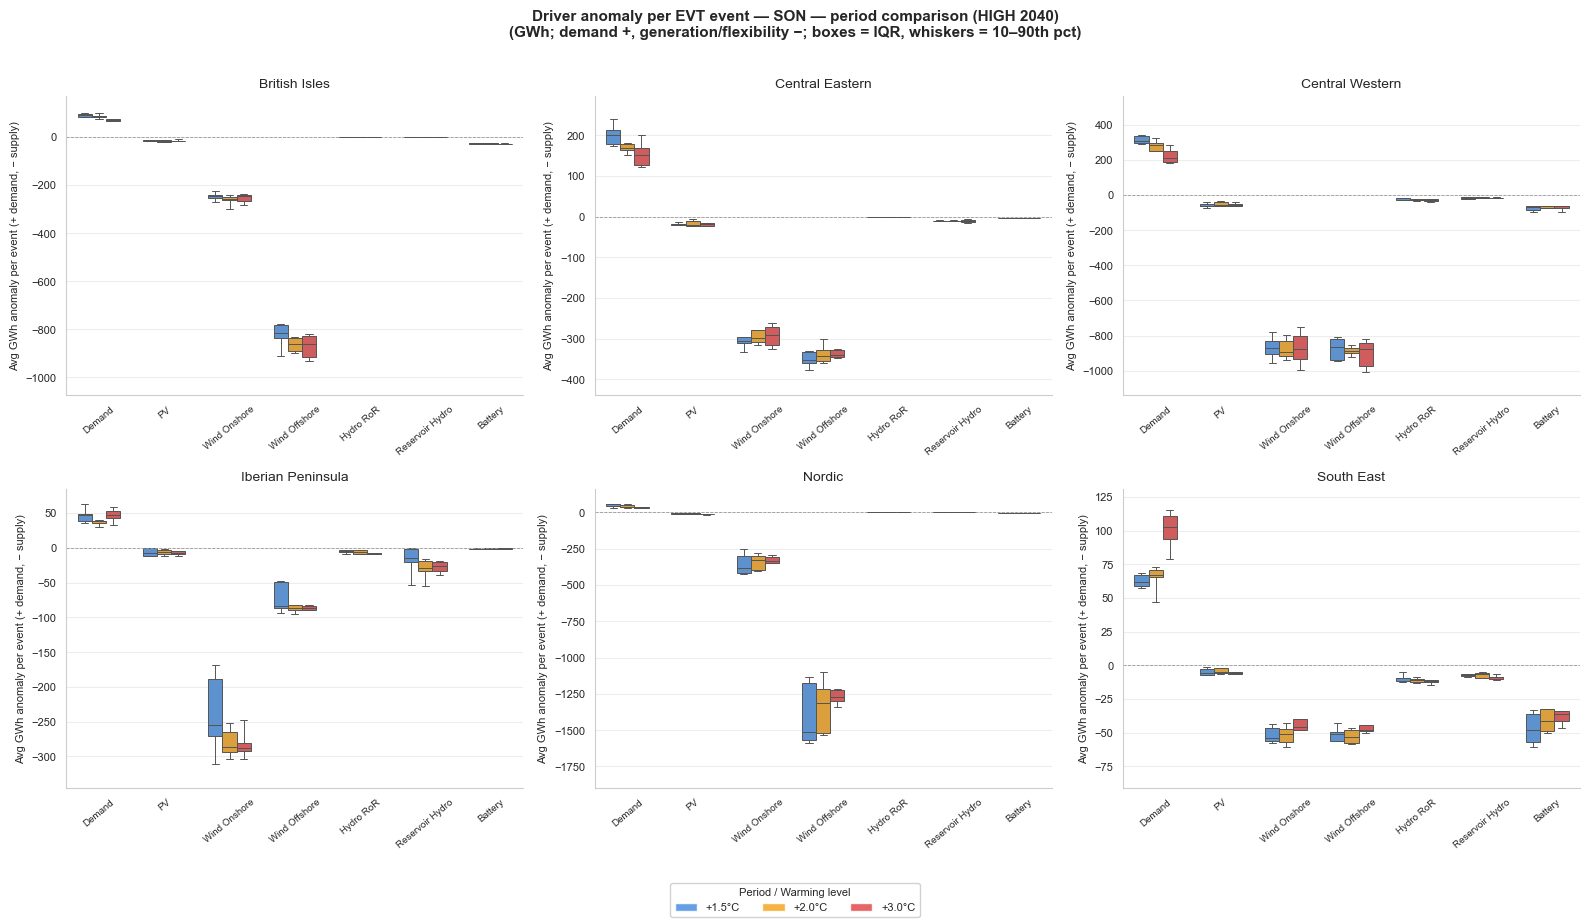

In [78]:
plot_seasonal_component_anomaly_distributions(
    df_seasonal_evt,
    zones=zones,
    season_order=season_order,
    period_defs=period_defs,
    component_cols=anomaly_component_cols,
    component_palette=driver_palette,
    period_palette=period_colors,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)

## Seasonal decomposition of EVT exceedances

Uses the **common annual threshold** (same for all seasons) to show which season
dominates absolute system-level stress. This is complementary to the season-specific
analysis above: it answers *when* extremes occur, not *how each season's tail evolves*.


df_seasonal: (162, 7)


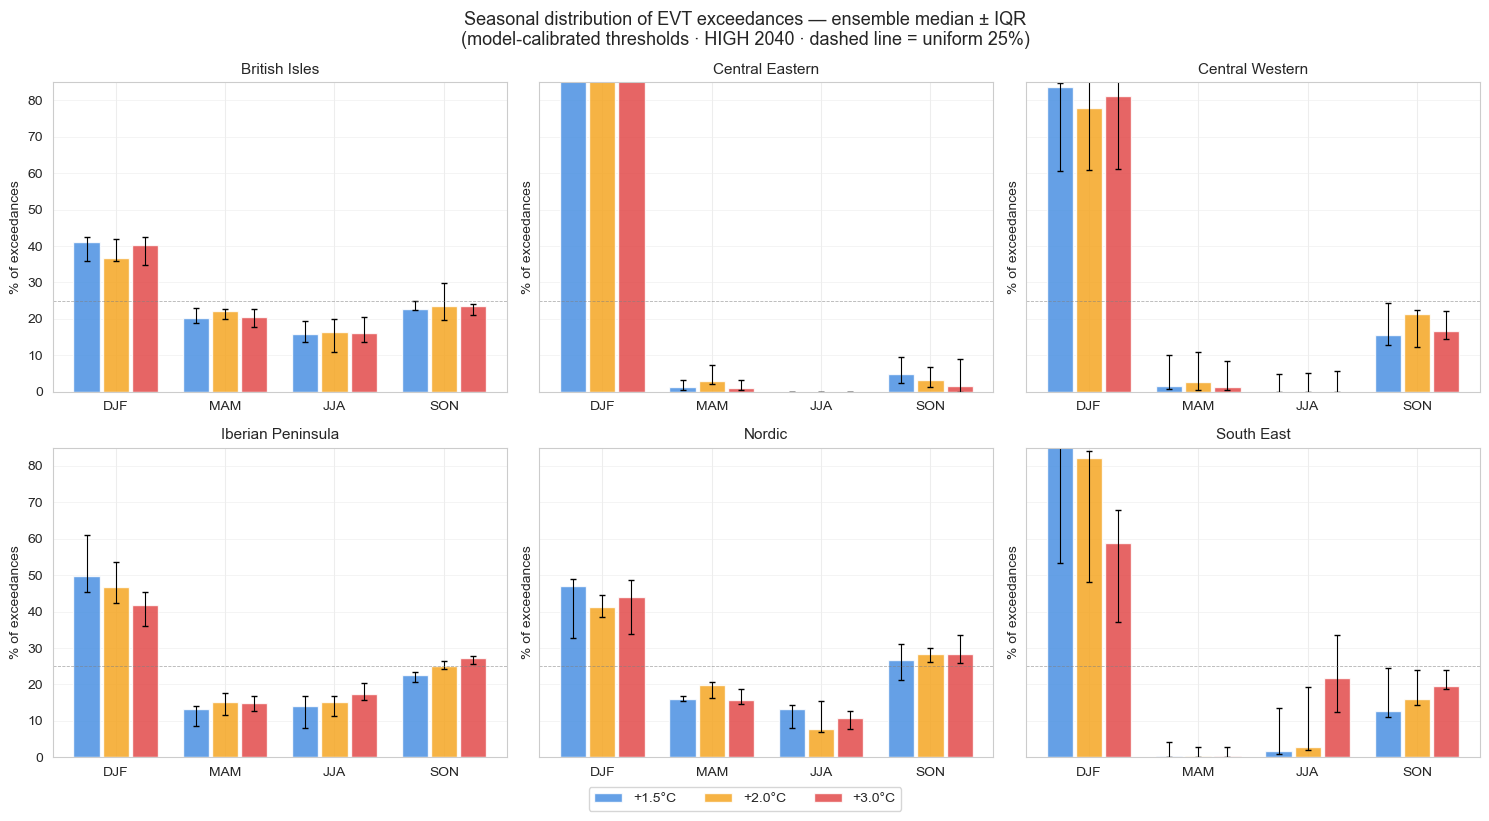

In [79]:
df_seasonal = compute_seasonal_exceedance_fractions(
    _cache_rl, evt_thresholds, period_defs, models, season_map, season_order
)
print(f"df_seasonal: {df_seasonal.shape}")

plot_seasonal_exceedance_distribution(
    df_seasonal,
    zones=zones,
    season_order=season_order,
    period_defs=period_defs,
    period_colors=period_colors,
    supply_scenario=supply_scenario,
    supply_year=supply_year,
)


## Seasonal co-occurrence of compound events

Co-occurrence is computed per season using the **common annual EVT threshold**.
For each zone-pair (A, B) and season, the fraction of Zone A exceedance timesteps
that fall within ±72 h of a Zone B exceedance is reported.

In [80]:
df_coo_seasonal = compute_zone_pair_cooccurrence(
    _cache_rl,
    season_evt_thresholds,  # {model: {zone: {season: float}}}
    period_defs,
    models,
    zones,
    season_map=season_map,
)
df_coo_seasonal.head()

,model,period,zone_a,zone_b,co_occurrence_pct,season
0,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,British_Isles,100.000000,MAM
1,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,Central_Eastern,13.242574,MAM
2,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,Central_Western,81.559406,MAM
3,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,Iberian_Peninsula,35.024752,MAM
4,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,+1.5°C,British_Isles,Nordic,9.158416,MAM


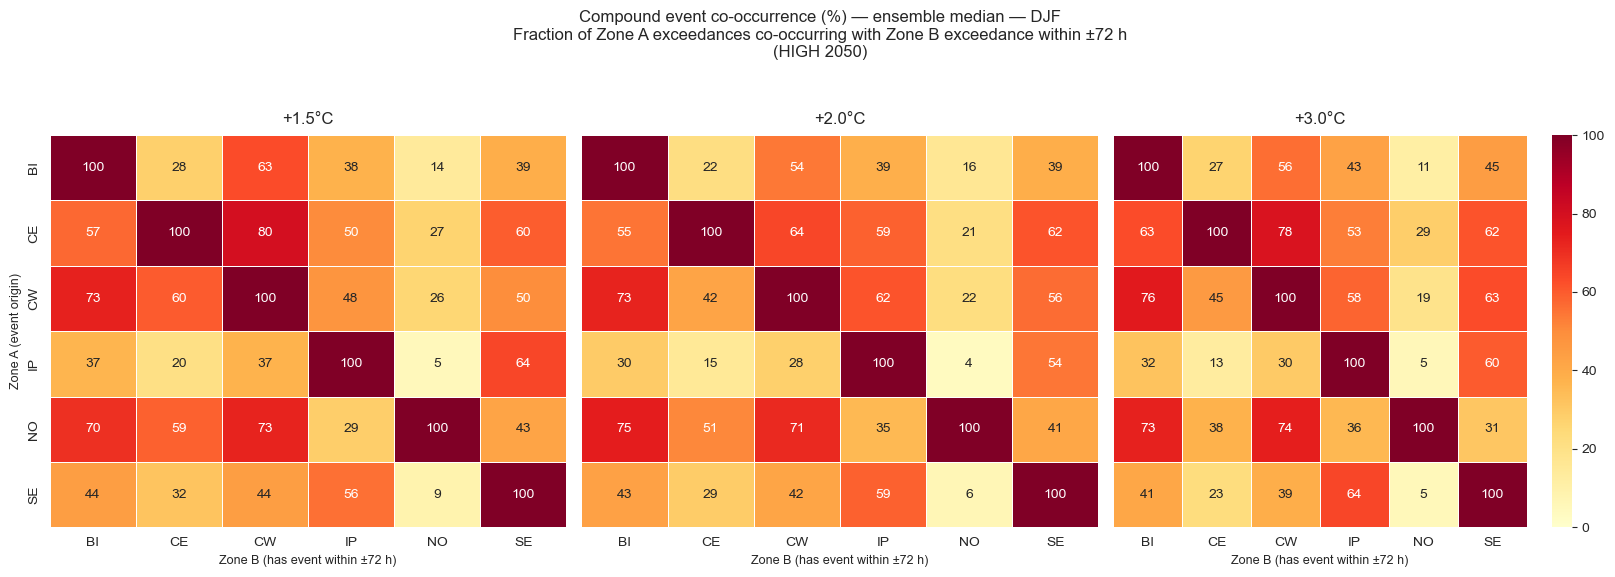

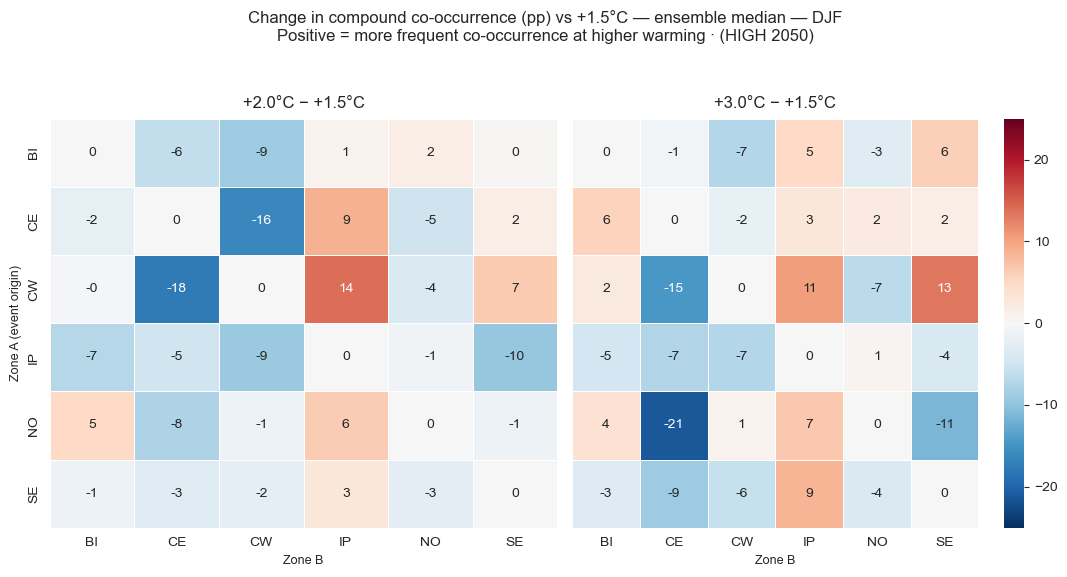

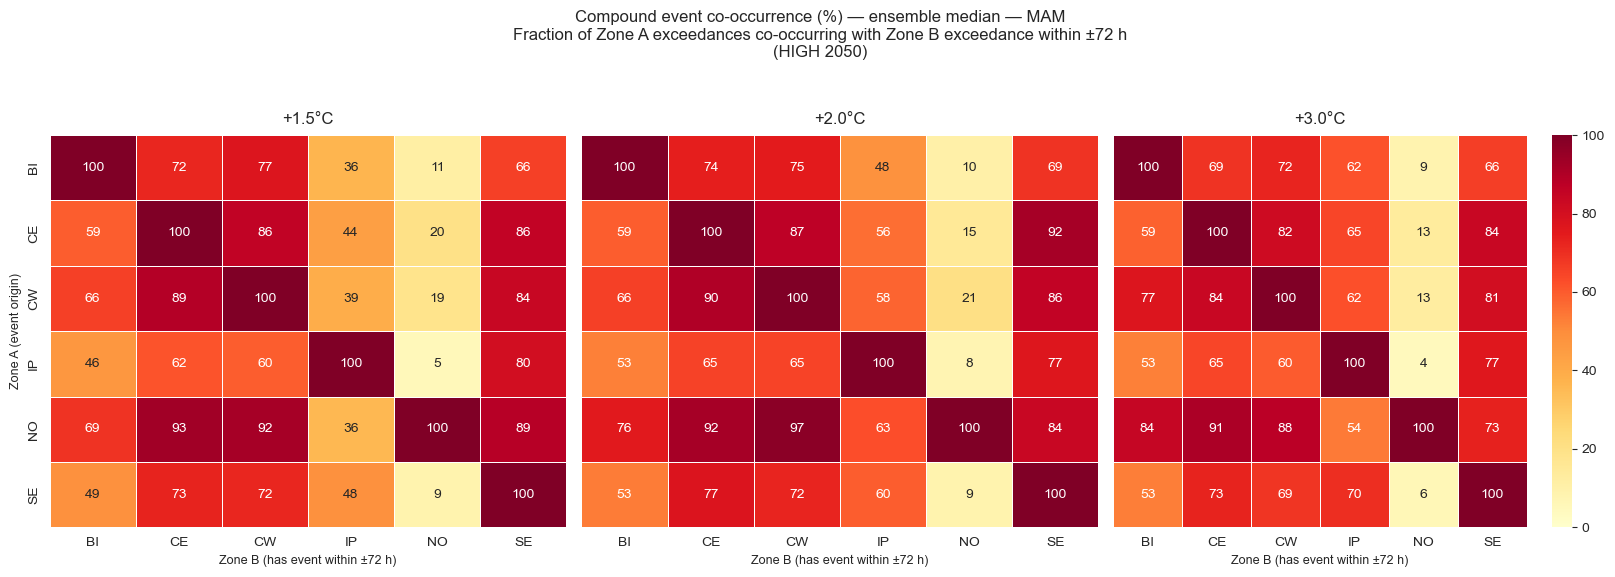

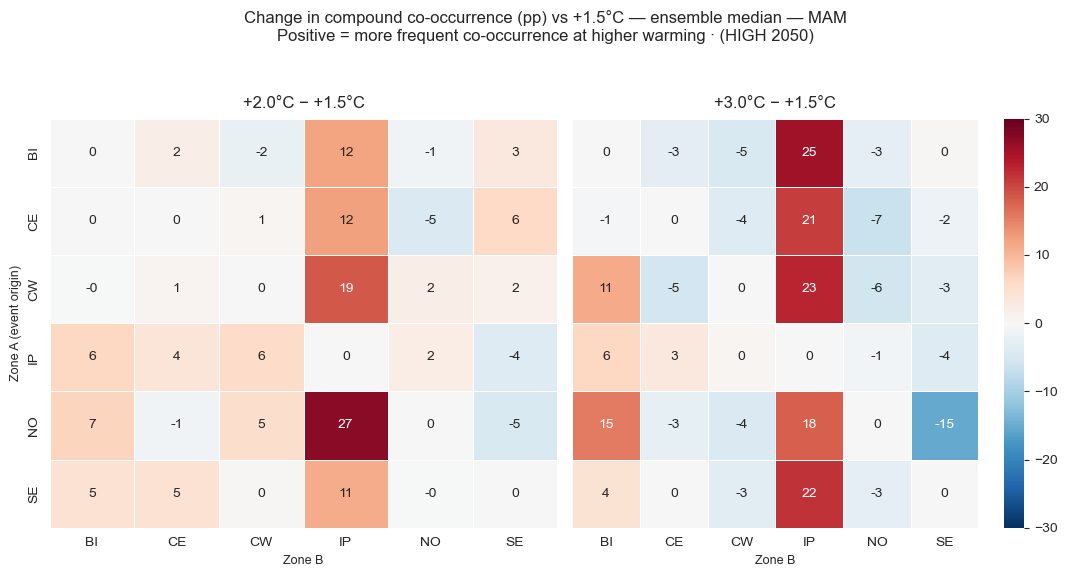

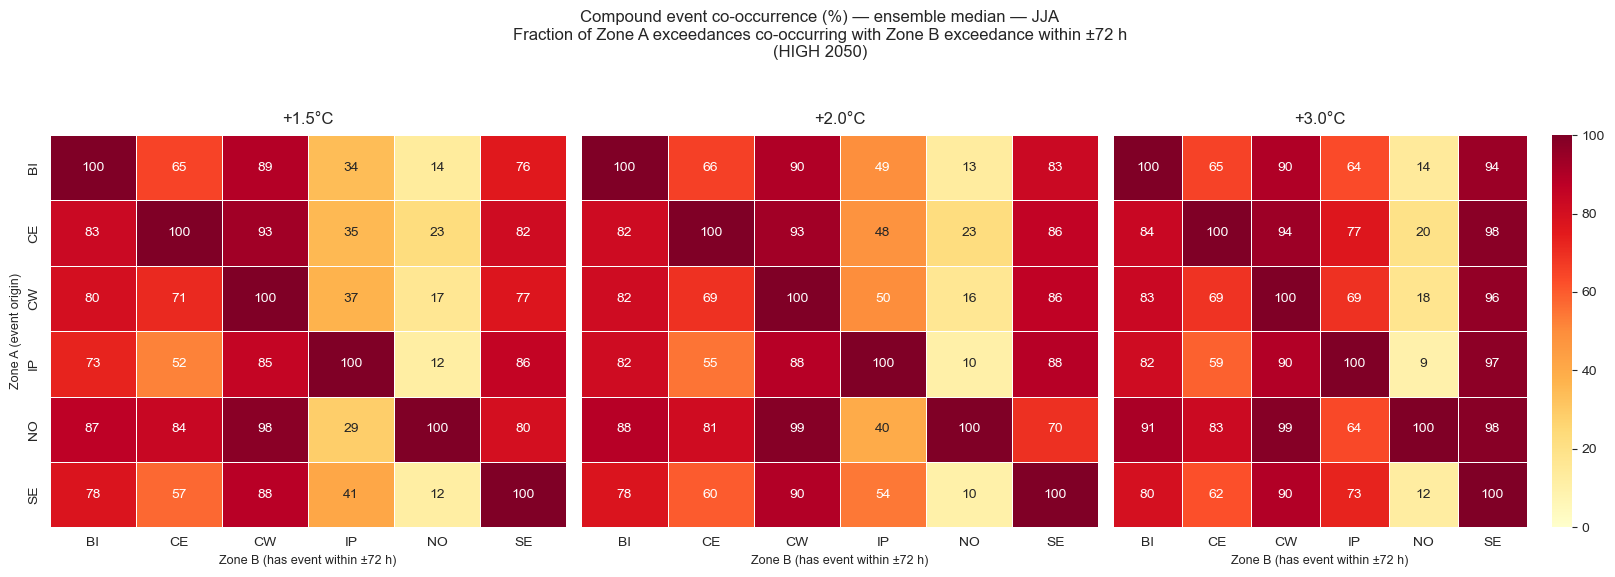

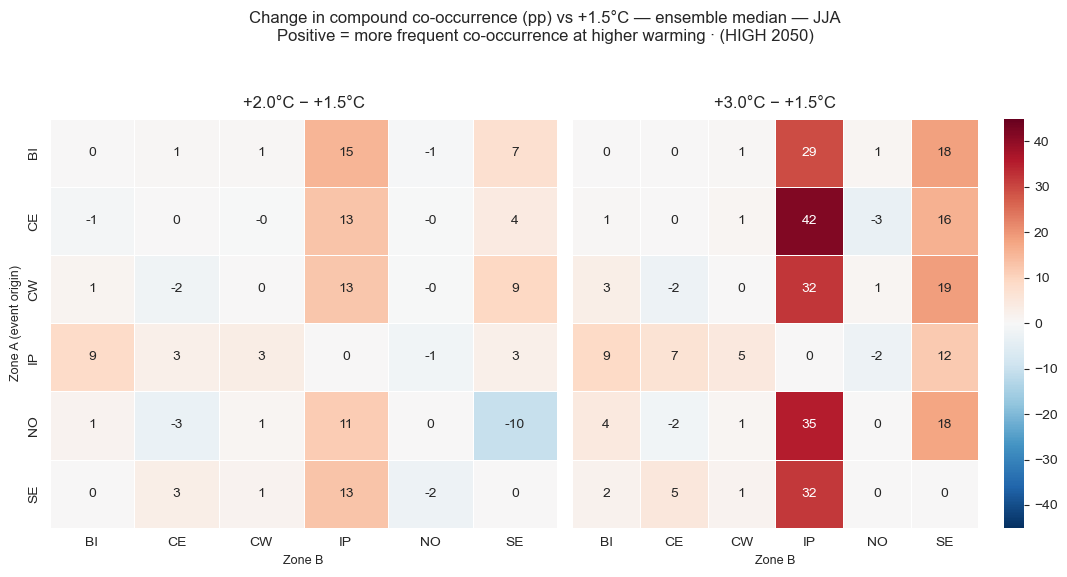

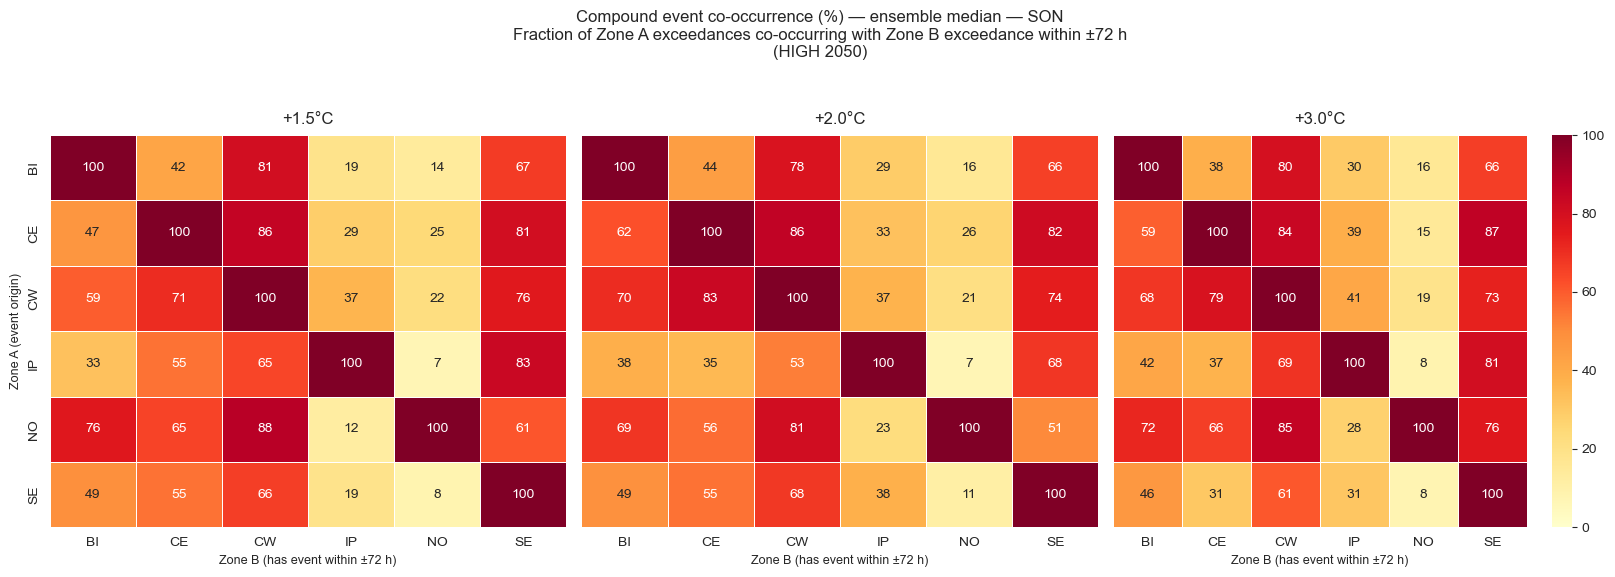

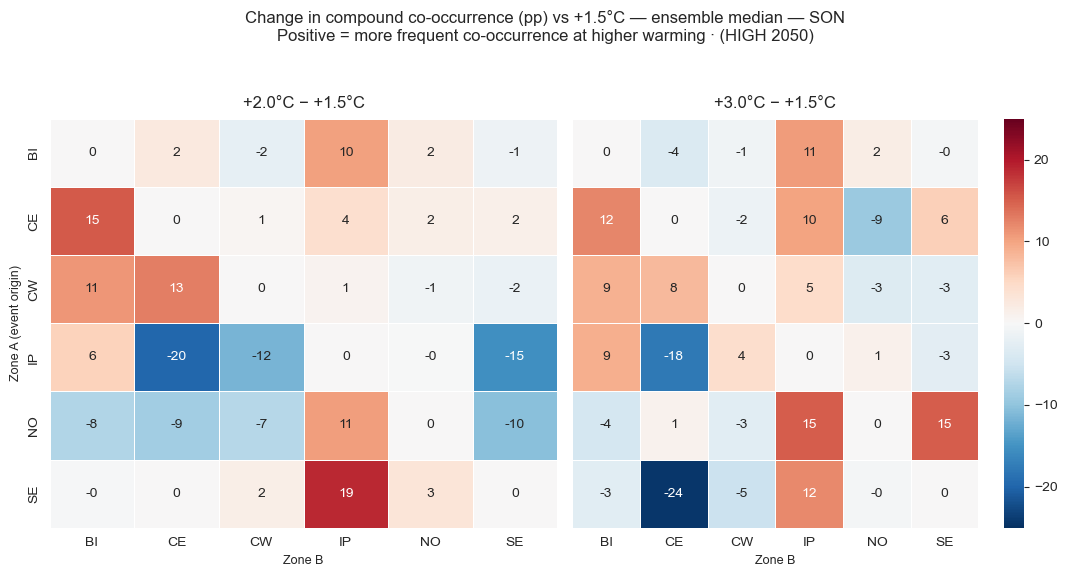

In [81]:
plot_zone_cooccurrence_heatmaps(
    df_coo_seasonal,
    zones=zones,
    period_defs=period_defs,
    season_order=season_order,
    supply_scenario=supply_scenario,
    supply_year=demand_year,
)

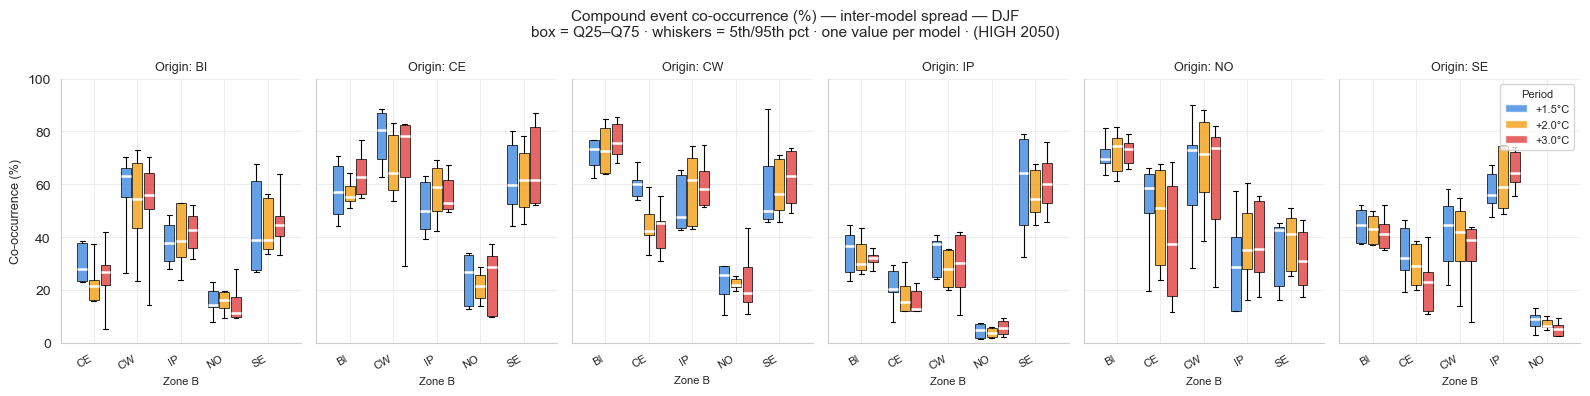

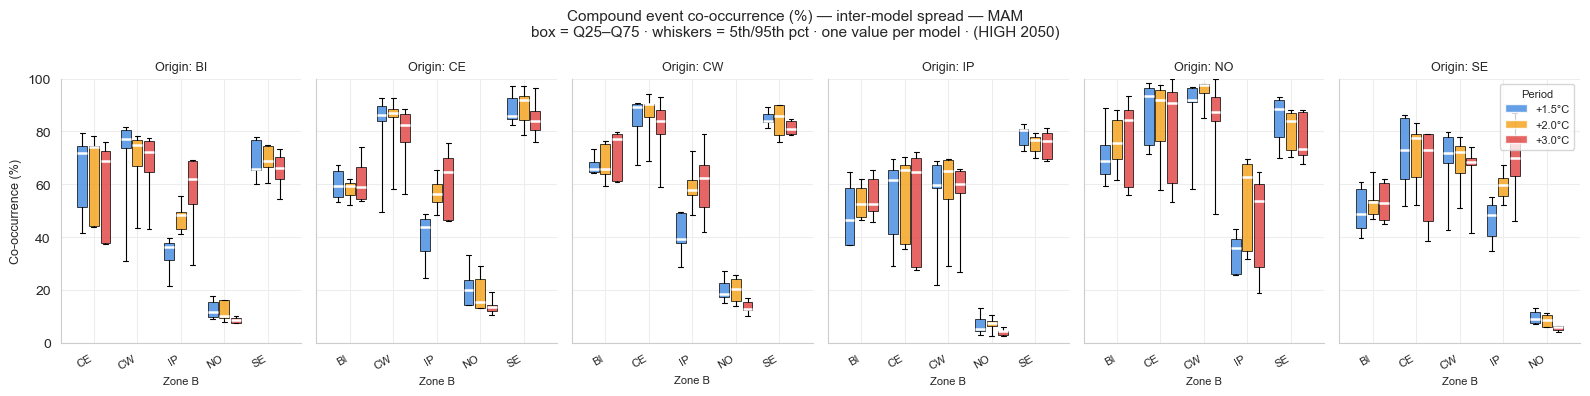

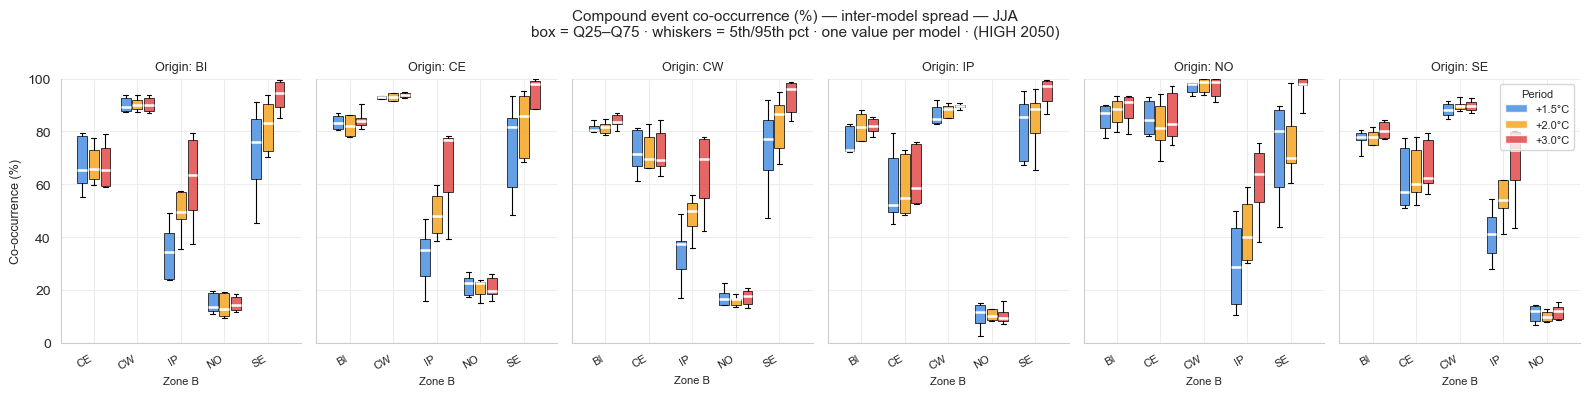

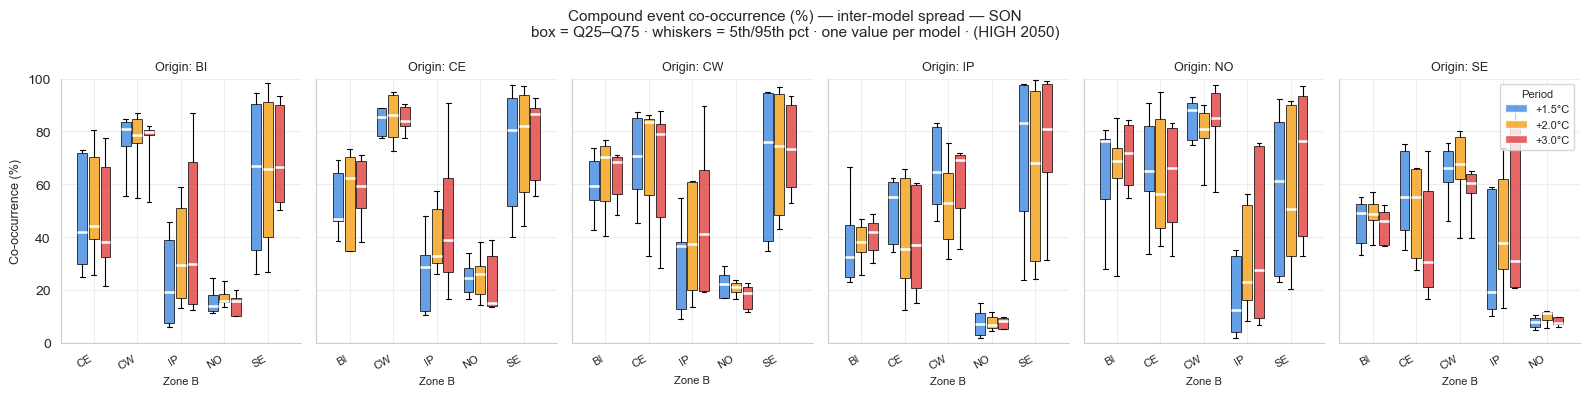

In [82]:
plot_zone_cooccurrence_boxplots(
    df_coo_seasonal,
    zones=zones,
    period_defs=period_defs,
    period_colors=period_colors,
    season_order=season_order,
    supply_scenario=supply_scenario,
    supply_year=demand_year,
    figsize=(16, 4)
)

## Seasonal unserved energy fraction

Share of seasonal electricity demand not met by generation after battery dispatch.
Computed per season, zone, model, and year — then aggregated to mean and worst year
per (model, period, zone, season) and merged into `df_seasonal_evt`.

In [83]:
df_use_seasonal_raw = compute_unserved_energy_fraction(
    _cache_rl,
    _cache_comp,
    period_defs,
    models,
    zones,
    season_map=season_map,
)

df_use_seasonal_agg = (
    df_use_seasonal_raw
    .groupby(["model", "period", "zone", "season"])["use_fraction"]
    .agg(Mean_USE_pct="mean", Max_USE_pct="max")
    .reset_index()
)
df_use_seasonal_agg["Mean_USE_pct"] *= 100
df_use_seasonal_agg["Max_USE_pct"]  *= 100
df_use_seasonal_agg = df_use_seasonal_agg.rename(columns={"period": "Period"})

df_seasonal_evt = df_seasonal_evt.merge(
    df_use_seasonal_agg,
    on=["model", "Period", "zone", "season"],
    how="left",
)
print(f"df_seasonal_evt: {df_seasonal_evt.shape[1]} columns, "
      f"USE range: {df_seasonal_evt['Mean_USE_pct'].min():.2f}% – "
      f"{df_seasonal_evt['Mean_USE_pct'].max():.2f}%")

df_seasonal_evt: 31 columns, USE range: 0.13% – 43.08%


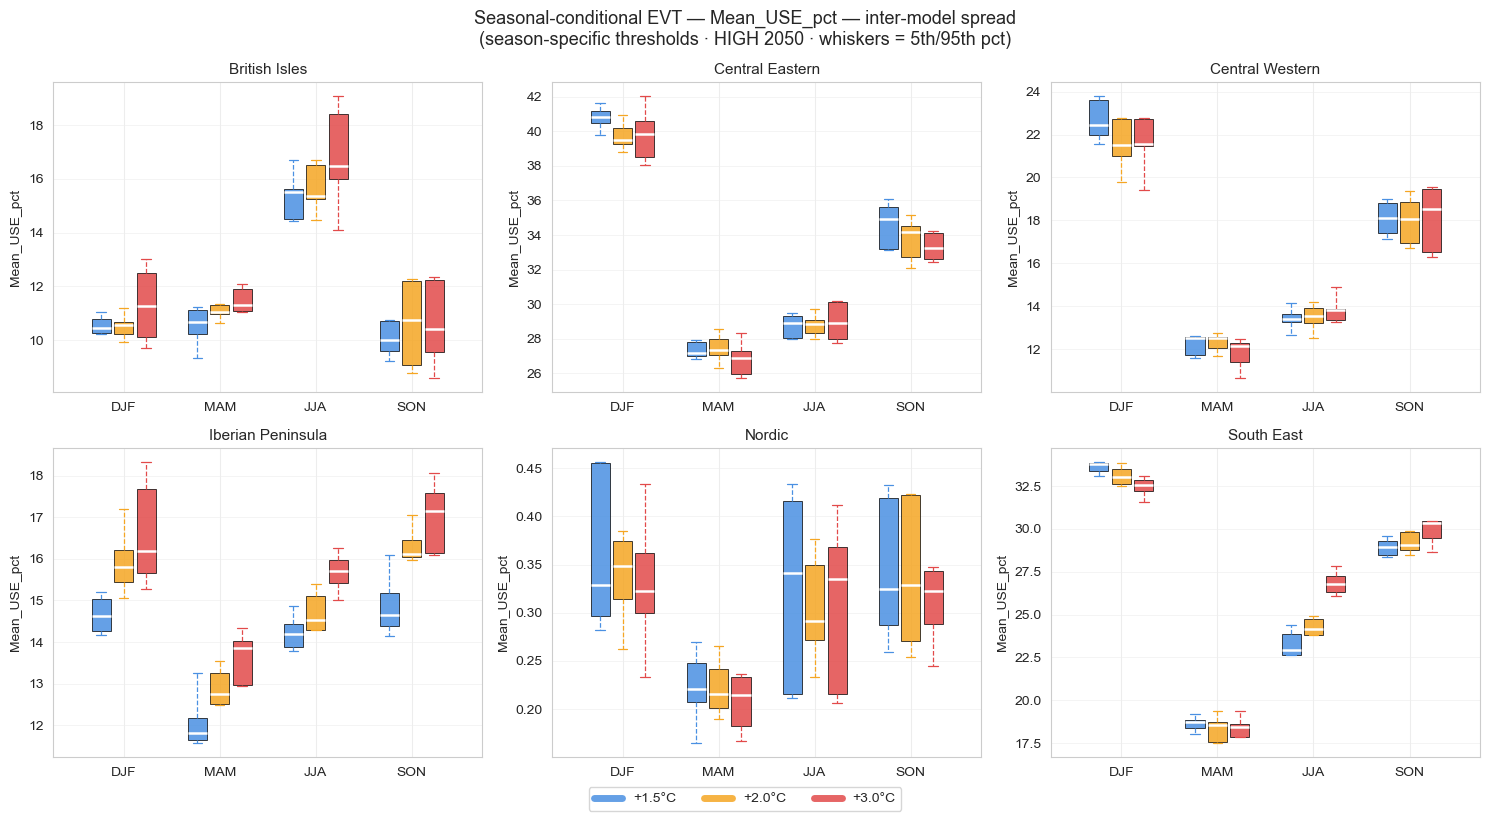

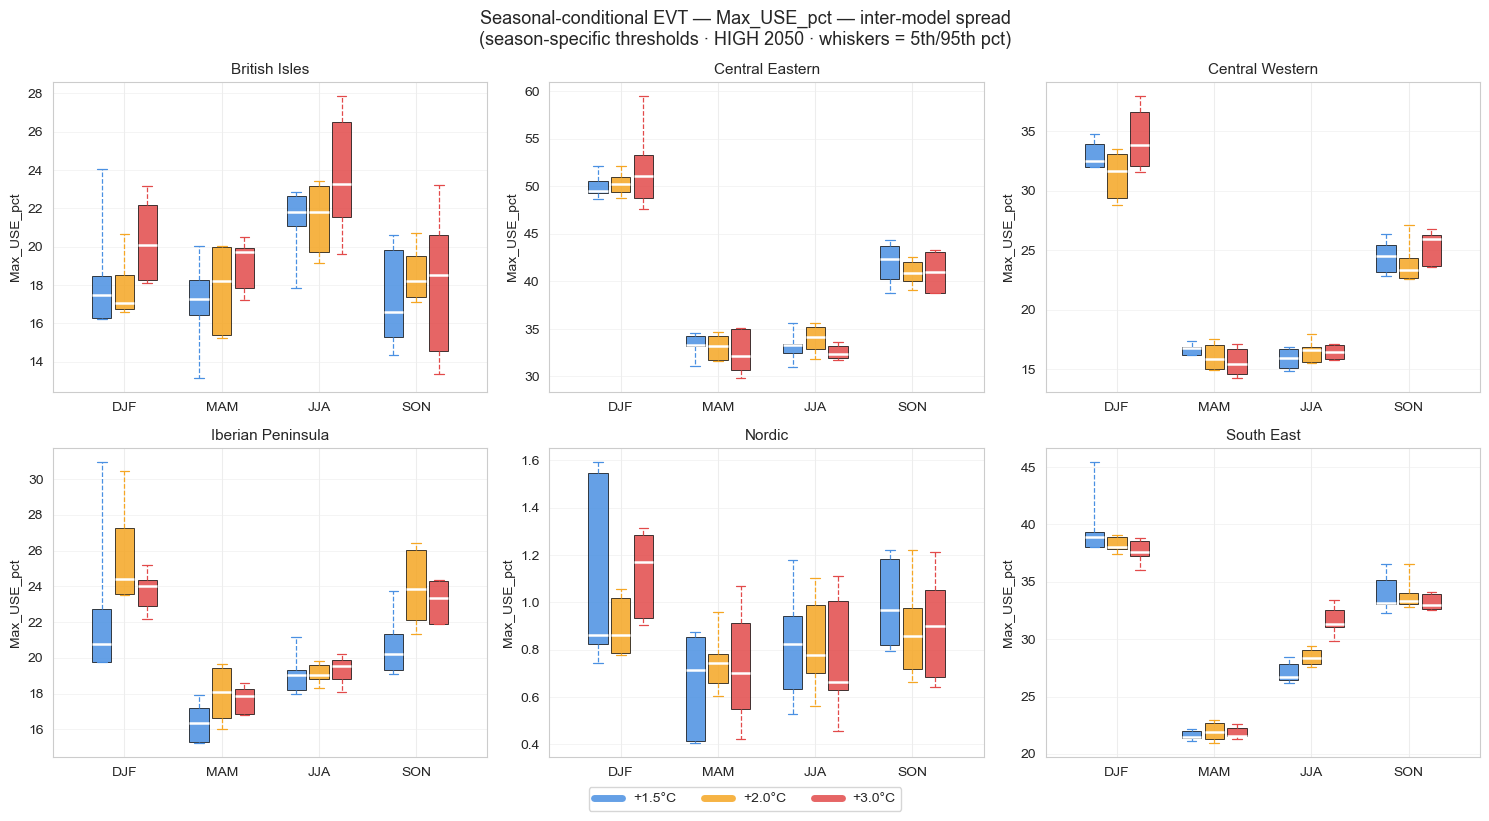

In [84]:
use_metrics = [
    ("Mean_USE_pct", "Mean seasonal unserved energy (%)", "Mean_USE_pct"),
    ("Max_USE_pct",  "Worst-year seasonal unserved energy (%)", "Max_USE_pct"),
]

for col, title_label, ylabel in use_metrics:
    plot_seasonal_conditional_metrics(
        df_seasonal_evt,
        metrics=[(col, ylabel, col)],
        zones=zones,
        period_defs=period_defs,
        season_order=season_order,
        period_colors=period_colors,
        supply_scenario=supply_scenario,
        supply_year=demand_year,
    )

## Seasonal flexibility attenuation

How much do battery and reservoir dispatch reduce the severity of extreme residual
load events **within each season**? For every detected exceedance event the function
reconstructs a counterfactual residual load (re-adding the dispatch at event
timesteps) and computes the percentage severity reduction that the flexibility
resource provides. Events are season-contained — non-season timesteps are masked to
`threshold − ε` before event detection so events cannot straddle season boundaries.

Seasonal thresholds from `season_evt_thresholds` are used, consistent with the EVT
analysis above.


In [85]:
df_flex_seasonal = compute_flexibility_attenuation_metrics(
    _cache_rl,
    _cache_comp,
    season_evt_thresholds,  # {model: {zone: {season: float}}}
    period_defs,
    models,
    zones,
    season_map=season_map,
)

# Rename to match df_seasonal_evt merge keys (period → Period, zone kept lowercase)
df_flex_seasonal = df_flex_seasonal.rename(columns={"period": "Period"})

df_seasonal_evt = df_seasonal_evt.merge(
    df_flex_seasonal[[
        "model", "Period", "zone", "season",
        "n_events",
        "battery_deployed_gwh_per_event",
        "prosumer_deployed_gwh_per_event",
        "utility_deployed_gwh_per_event",
        "reservoir_deployed_gwh_per_event",
        "battery_attenuation_pct",
        "prosumer_attenuation_pct",
        "utility_attenuation_pct",
        "reservoir_attenuation_pct",
        "combined_attenuation_pct",
    ]],
    on=["model", "Period", "zone", "season"],
    how="left",
    suffixes=("", "_flex"),
)

print(f"df_seasonal_evt: {df_seasonal_evt.shape[1]} columns after flexibility merge")
df_seasonal_evt.groupby(["zone", "season", "Period"])["battery_attenuation_pct"].median().unstack("Period").round(1)

df_seasonal_evt: 41 columns after flexibility merge


Period                    +1.5°C  +2.0°C  +3.0°C
zone              season                        
British_Isles     DJF       17.7    18.6    19.0
                  JJA       15.4    15.8    14.9
                  MAM       20.6    19.4    20.1
                  SON       22.0    20.8    20.3
Central_Eastern   DJF       16.6    17.7    17.4
                  JJA       48.0    47.4    45.3
                  MAM       30.8    30.6    30.9
                  SON       20.9    23.5    22.3
Central_Western   DJF       15.9    17.5    17.9
                  JJA       40.4    40.7    40.1
                  MAM       42.8    41.4    43.0
                  SON       27.0    26.5    27.0
Iberian_Peninsula DJF       48.5    45.5    51.6
                  JJA       65.6    58.7    56.1
                  MAM       65.2    56.8    57.2
                  SON       62.6    54.2    60.3
Nordic            DJF       15.5    13.6    15.9
                  JJA       29.4    30.7    26.9
                  MAM       23.9    22.9    22.9
                  SON       17.9    19.1    20.7
South_East        DJF       51.5    49.9    47.5
                  JJA       70.1    69.0    64.0
                  MAM       67.2    69.0    71.0
                  SON       56.8    56.3    55.2

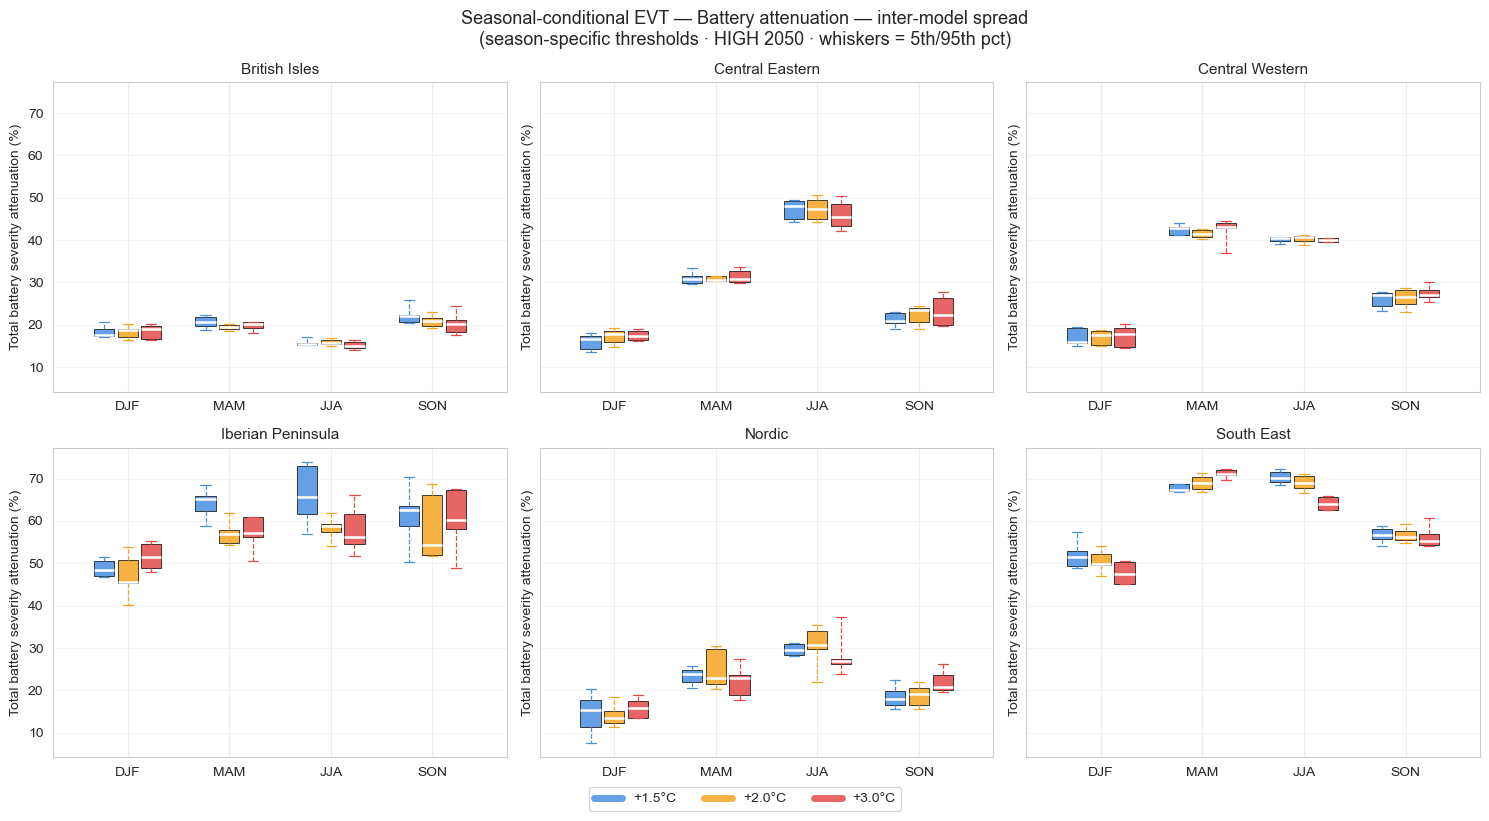

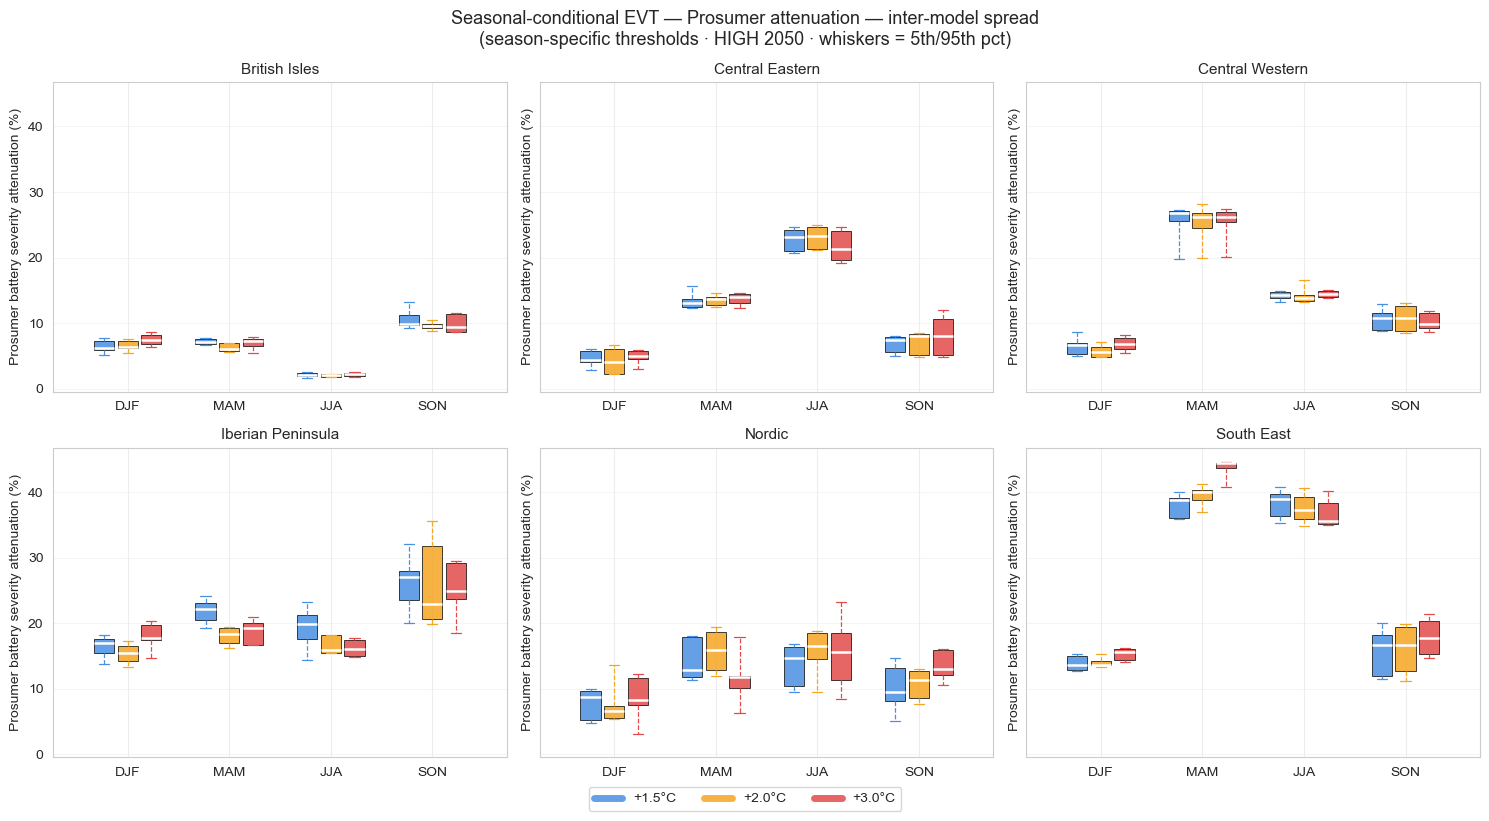

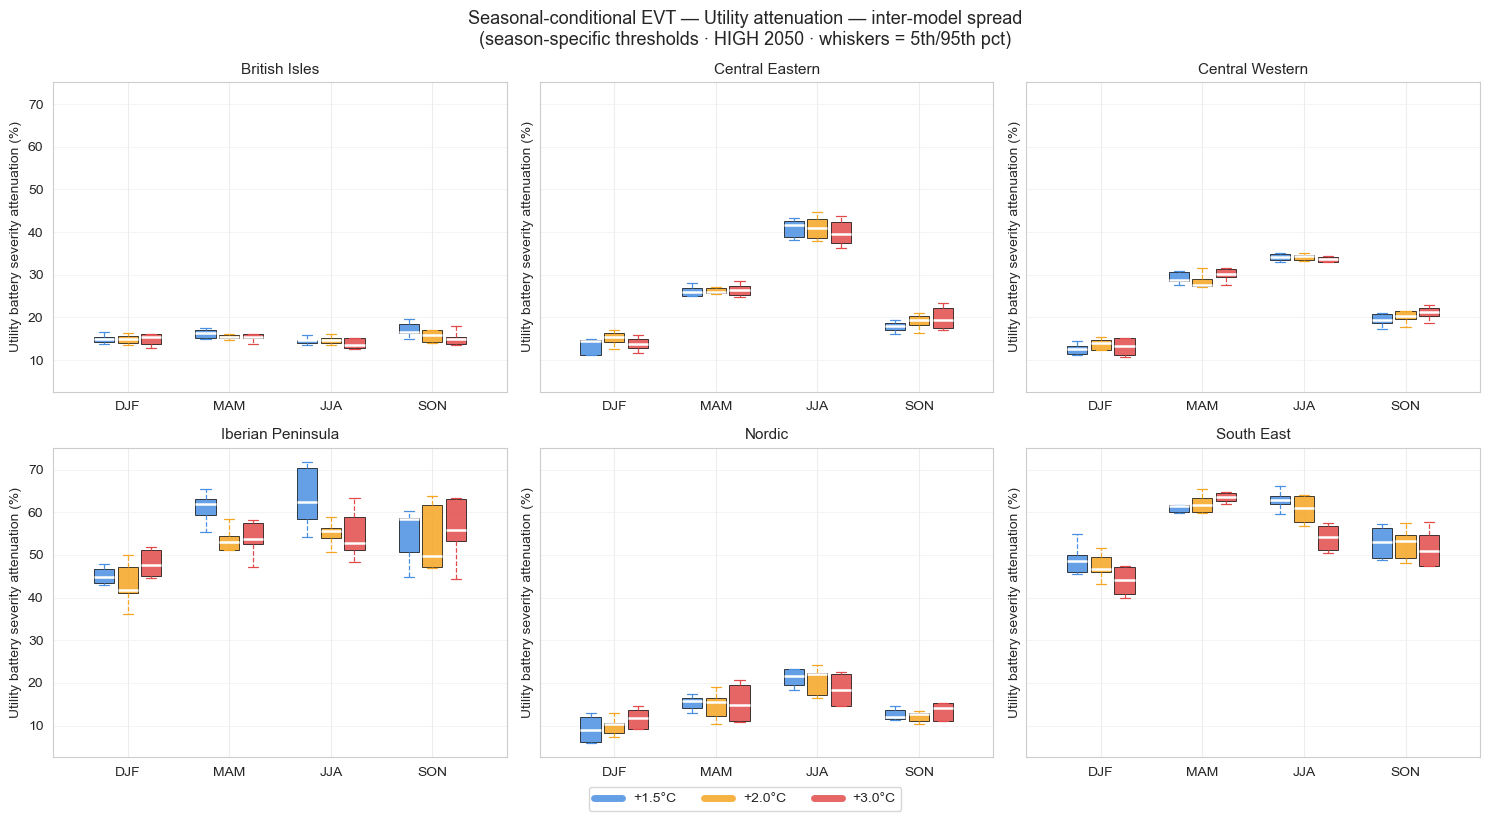

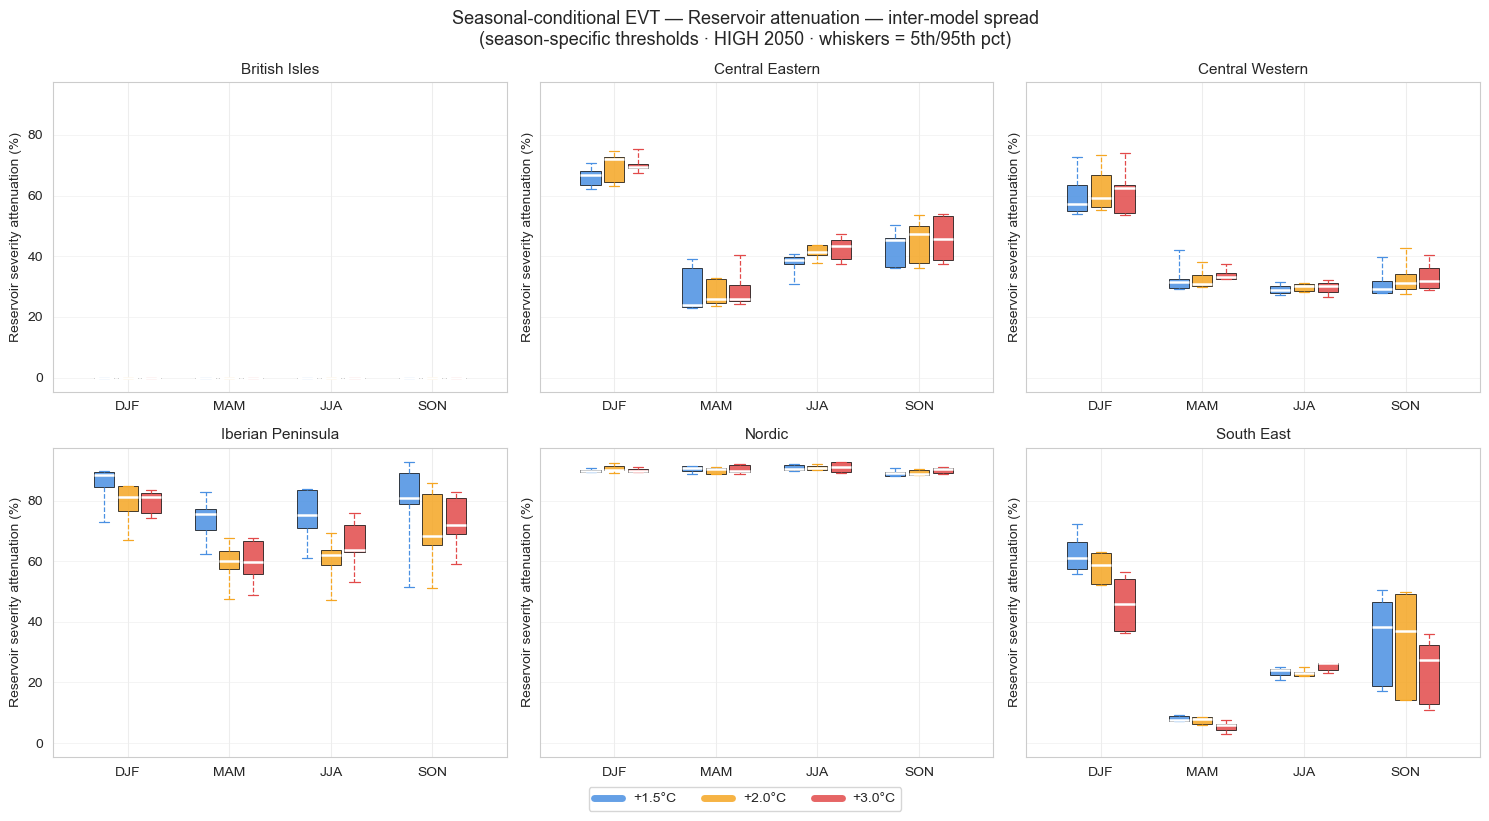

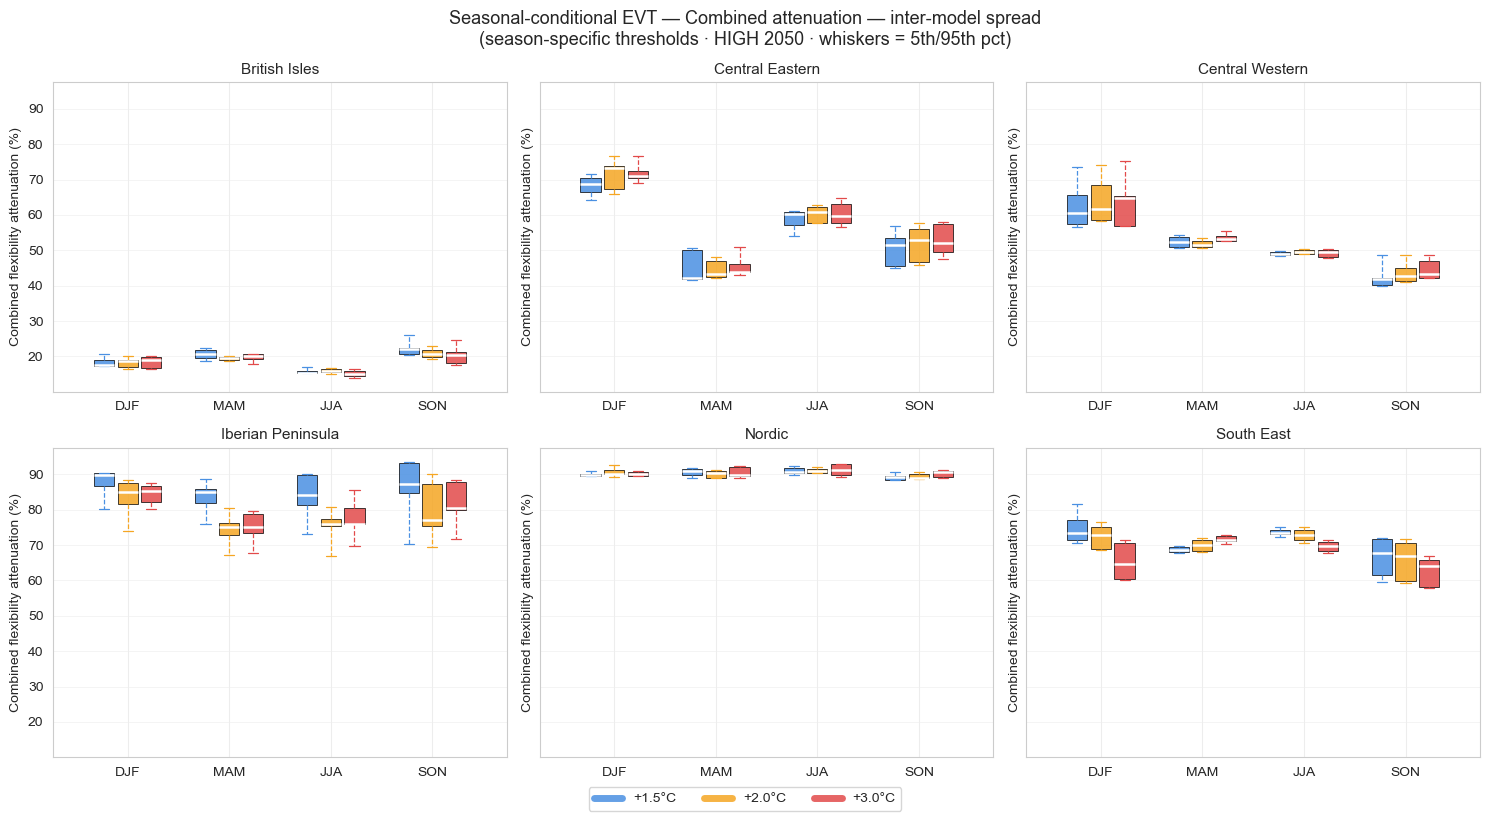

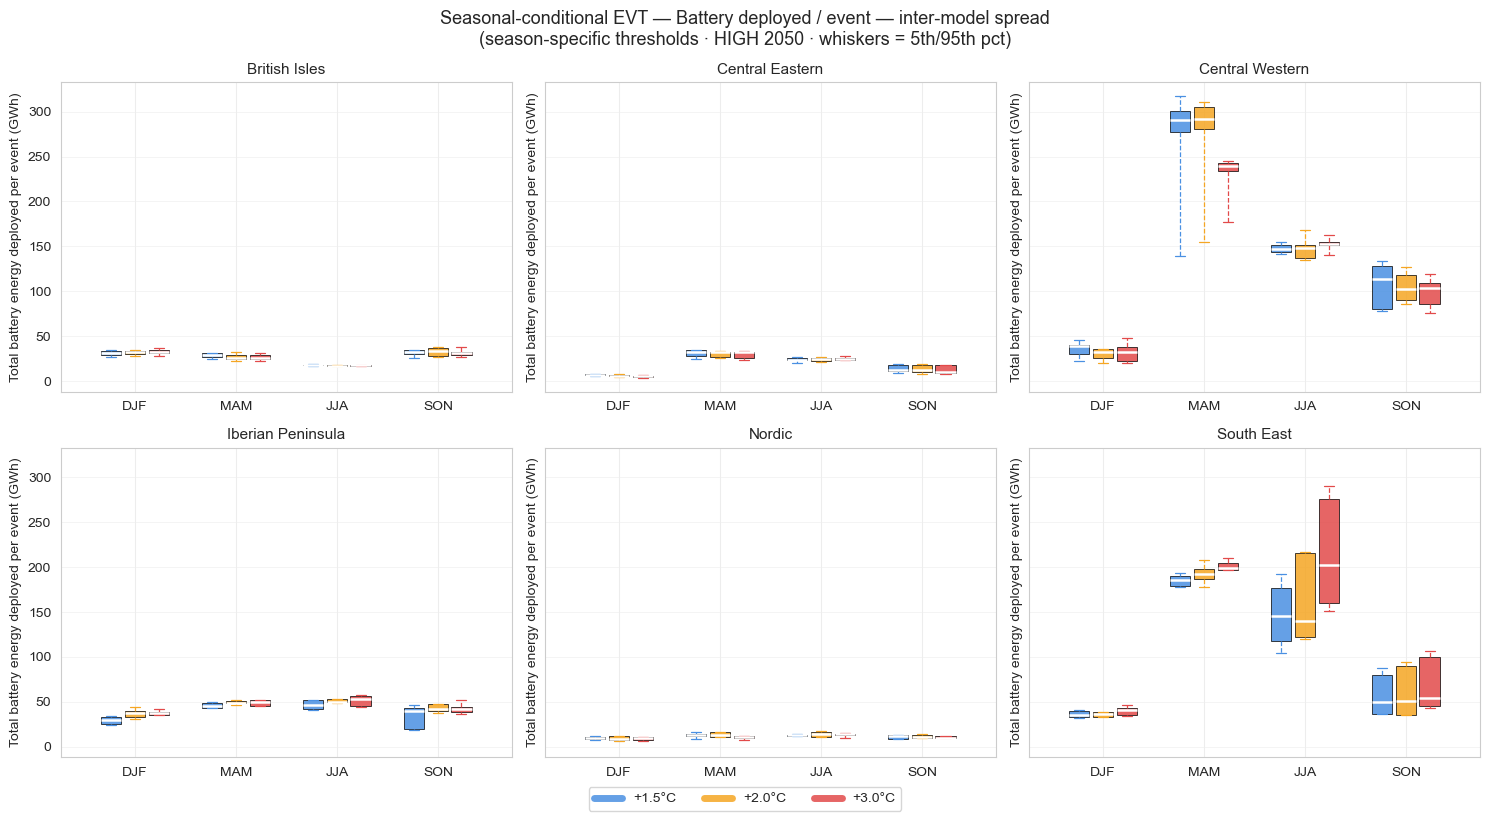

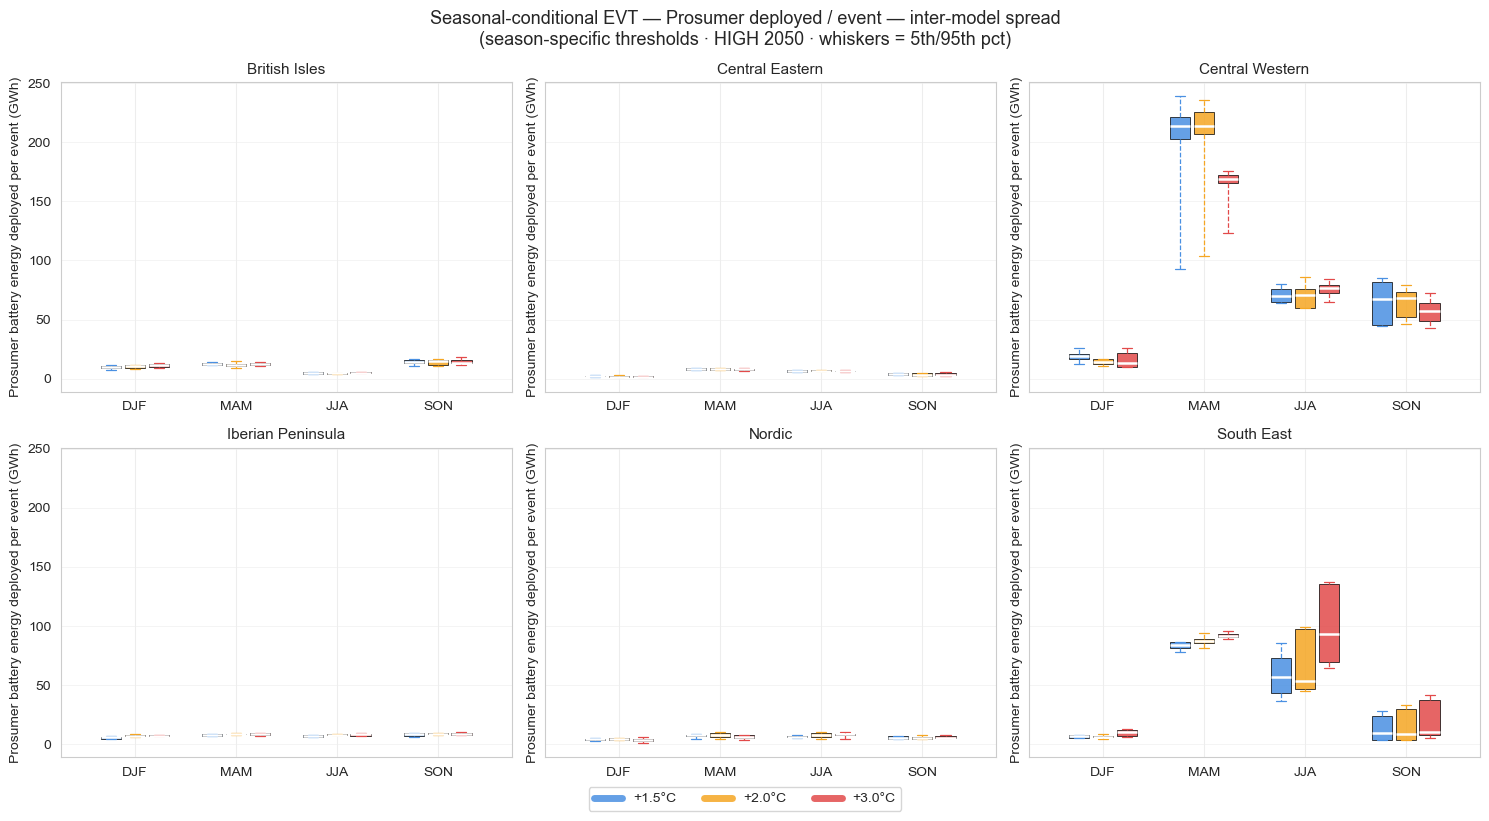

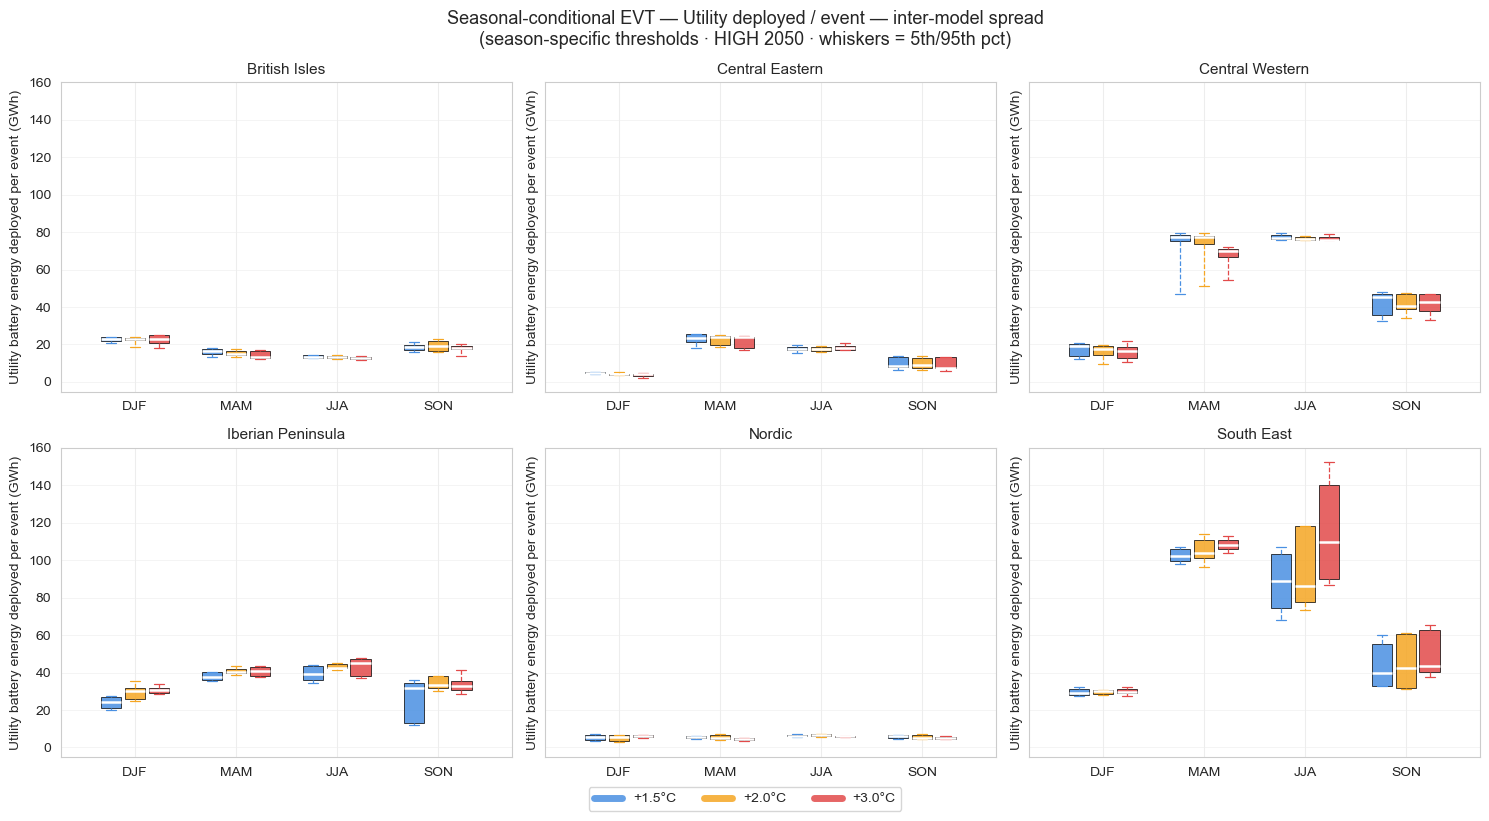

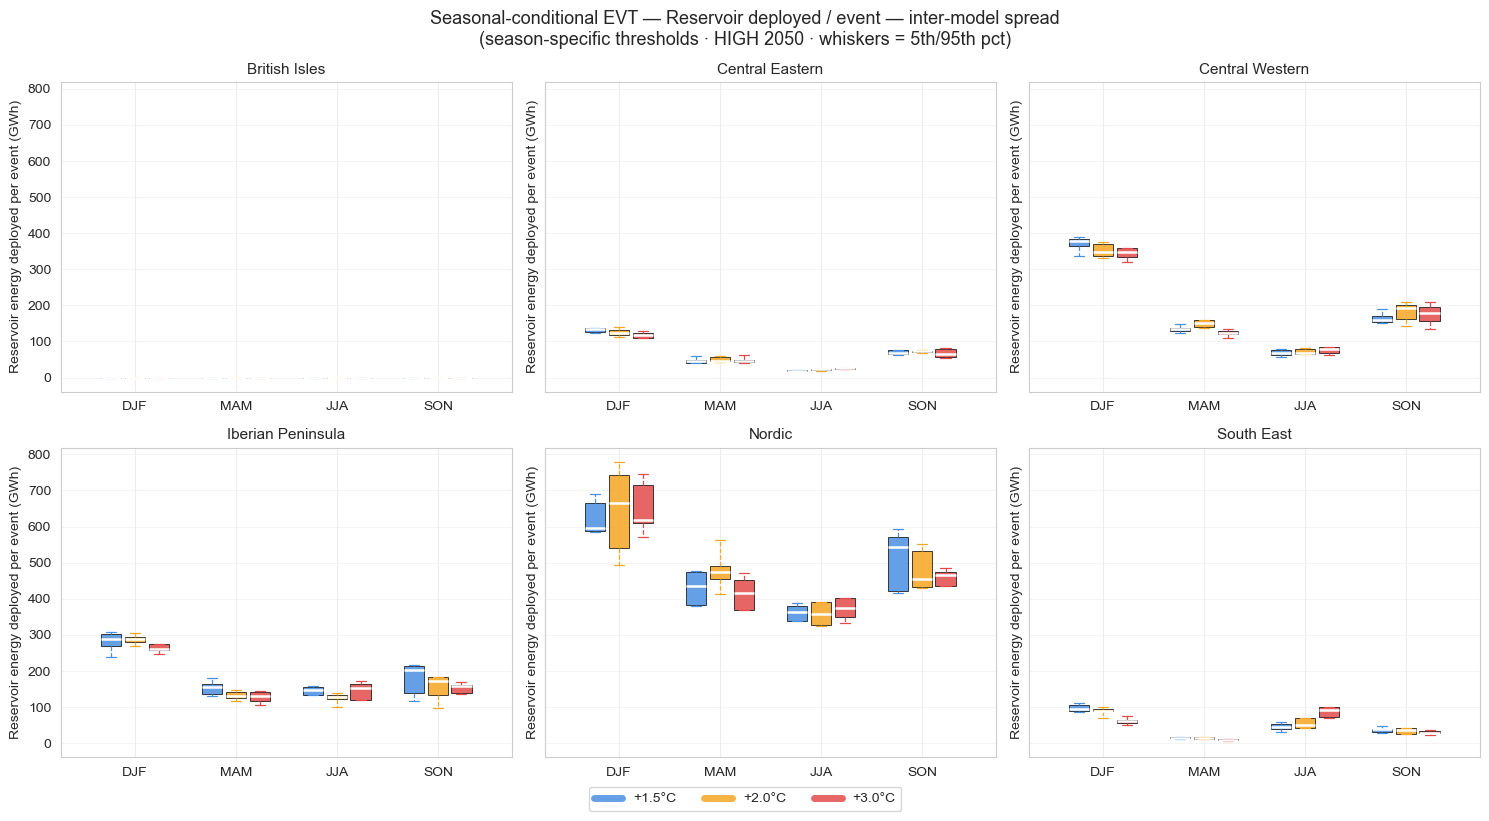

In [86]:
flex_metrics = [
    # ── Attenuation ───────────────────────────────────────────────────────────
    (
        "battery_attenuation_pct",
        "Total battery severity attenuation (%)",
        "Battery attenuation",
    ),
    (
        "prosumer_attenuation_pct",
        "Prosumer battery severity attenuation (%)",
        "Prosumer attenuation",
    ),
    (
        "utility_attenuation_pct",
        "Utility battery severity attenuation (%)",
        "Utility attenuation",
    ),
    (
        "reservoir_attenuation_pct",
        "Reservoir severity attenuation (%)",
        "Reservoir attenuation",
    ),
    (
        "combined_attenuation_pct",
        "Combined flexibility attenuation (%)",
        "Combined attenuation",
    ),
    # ── Deployed energy ───────────────────────────────────────────────────────
    (
        "battery_deployed_gwh_per_event",
        "Total battery energy deployed per event (GWh)",
        "Battery deployed / event",
    ),
    (
        "prosumer_deployed_gwh_per_event",
        "Prosumer battery energy deployed per event (GWh)",
        "Prosumer deployed / event",
    ),
    (
        "utility_deployed_gwh_per_event",
        "Utility battery energy deployed per event (GWh)",
        "Utility deployed / event",
    ),
    (
        "reservoir_deployed_gwh_per_event",
        "Reservoir energy deployed per event (GWh)",
        "Reservoir deployed / event",
    ),
]

plot_seasonal_conditional_metrics(
    df_seasonal_evt,
    metrics=flex_metrics,
    zones=zones,
    period_defs=period_defs,
    season_order=season_order,
    period_colors=period_colors,
    supply_scenario=supply_scenario,
    supply_year=demand_year,
    sharey=True
)